[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/QNN_AdversarialGeneralization_Georgiou2025.ipynb)

# Generalisation of adversarially trained quantum classifiers: Georgiou et al. (2025) step by step

**Paper.** Petros Georgiou, Aaron Mark Thomas, Sharu Theresa Jose and Osvaldo Simeone, *On the Generalization of Adversarially Trained Quantum Classifiers*, arXiv:2504.17690 [quant-ph], April 2025 (University of Birmingham and King's College London). DOI [10.48550/arXiv.2504.17690](https://doi.org/10.48550/arxiv.2504.17690).

**What this notebook does.** A quantum classifier can be *adversarially trained*: instead of minimising the loss on the training inputs, it minimises the loss on the inputs after an attacker has nudged them. The paper proves how much worse such a classifier does on new data than on its training data (the *generalisation error*) and how this depends on the way the data are embedded in the qubits. The notebook

1. draws data from the paper's own Gaussian generator (no external data set exists in this paper);
2. builds the paper's classifier (angle or amplitude embedding, four `StronglyEntanglingLayers`, read-out of `<Z>` on all qubits) as an **exact simulator that is asserted equal to the real PennyLane QNode**, values and gradients;
3. adversarially trains it with FGSM and measures conventional and adversarial generalisation errors against the data dimension d (paper Figs. 4 and 5), the number of training samples m (Fig. 1 and the 1/sqrt(m) claim) and, for the quantum attack of Section VII B, against the attack strength for noiseless and noisy embeddings (Fig. 6);
4. computes the paper's bounds (Theorems 1 to 4, Proposition 1) on the same training samples and puts them next to the measured errors;
5. trains a classical adversarially trained linear model, a random forest and an RBF-SVC on identical inputs;
6. prints the paper's claims next to the measured outcomes with one verdict per claim.

**How to run.** Colab, CPU runtime, *Runtime -> Run all*. `FAST_MODE = True` is a class demo of about ten minutes; `FAST_MODE = False` uses the larger budgets written next to each constant in the configuration cell. All circuits are simulated exactly on the CPU (the paper simulates them too); no quantum hardware, no token and no download are needed.

**What you get at the end.** Data and circuit figures, the measured-versus-bound figures for classical and quantum attacks, a scaling plot in m, a baseline table, and a table of verdicts for the paper's claims, followed by a critical reading and exercises.

## The paper in one page

**Problem.** Adversarial training replaces the usual loss by the loss at the worst-case perturbed input. For classical networks it is known that this makes the gap between training and test loss (the *generalisation error*) larger. The paper asks how large the gap is for quantum classifiers, and how the choice of quantum embedding changes it, for two kinds of attacker: a *classical* attacker who perturbs the input vector x inside an l_p ball of radius eps, and a *quantum* attacker who perturbs the embedded state rho(x) inside a Schatten-p ball of radius eps.

**Model.** The score is `f(x) = Tr(A rho(x))` and the label is its sign. The observable A is any Hermitian matrix with bounded r-Schatten norm (`||A||_r <= b`); in practice `A = V^dagger Z_1 V` for a trained unitary V (Remark 1). Embeddings: *angle* (`U(x) = prod_j exp(-i x_j sigma_Y)`, n = d qubits), *dense* angle (n = d/2), L-layer data re-uploading, and *amplitude* (`|psi(x)> = sum_i x_i/||x|| |i>`, n = ceil(log2 d) qubits).

**Method (theory).** With a bounded, eta-Lipschitz, non-increasing loss `phi(y f(x))`, the generalisation error is bounded with probability 1 - delta by `2 * Rademacher complexity + 3B sqrt(ln(2/delta)/(2m))` (Theorem 1). Theorem 2 bounds the ordinary Rademacher complexity R(F) of the observable class. Theorem 3 bounds the *adversarial* one: `ARC <= R(F) + b S J(r)/sqrt(m)`, where `S = dH * sup ||rho(x) - rho(x')||_{r/(r-1)}` measures how fast the embedding moves under the attack (classical attack) or is `eps max{dH, dH^(2-1/r-1/p)}` (quantum attack), and J(r) is a constant from Dudley's integral. Proposition 1 evaluates S per embedding (Table I of the paper): for rotation embeddings the excess term decays exponentially with d, for amplitude embedding it grows at most linearly with d, for quantum attacks it depends on the embedding only through the Hilbert-space dimension dH. Theorem 4 gives a tighter two-sided bound for *noisy* embeddings whose smallest eigenvalue is at least eps. Theorem 5 extends everything to K classes.

**Numerical claims (Section VII, Figs. 1, 4, 5, 6).** Equiprobable labels, x | y ~ N(mu_y, I_d) with `mu_0 = (pi/4) 1_d` and `mu_1 = (pi/4)(1_{floor(d/2)}, -1_{d-floor(d/2)})`; m = 20 training samples, 1000 samples for the population risk; four strongly entangling layers followed by Pauli-Z measurements on all qubits; loss `1/(1+exp(alpha f))` with alpha = 10; adversarial training for 40 epochs with FGSM at eps = 0.3 (p = infinity). (i) With **angle** embedding the adversarial and conventional generalisation errors converge as d grows; (ii) with **amplitude** embedding they diverge; (iii) with a **quantum FGSM** attack on 3-qubit amplitude-embedded states (d = 6), the adversarial generalisation error grows with eps, and a **noisy** embedding (global depolarising noise, smallest eigenvalue 0.011) generalises better than the noiseless one; (iv) the excess error scales as 1/sqrt(m) (Fig. 1 and the abstract). The paper reports figures only; it gives no table of numbers, so the verdicts below are about trends, orderings and inequalities.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data | Gaussian mixture, `mu_y` as above, equiprobable labels | identical generator, drawn inside the notebook (no download) |
| Data dimensions d | x-axis of Figs. 4 and 5, values not stated | `D_LIST` (2 to 8 in FAST mode, 2 to 10 in the full run); angle embedding needs d qubits, 10 is the limit of a shared CPU |
| Training set / test set | m = 20 / 1000 samples | identical |
| Classifier | 4 strongly entangling layers, Pauli-Z on all qubits, `r = infinity` observable | identical; the score is the **mean** of the n expectations `<Z_i>` (CHOICE: the paper does not say how n outputs become one score; the mean keeps `||A||_inf <= 1`, so b = 1) |
| Angle embedding | `exp(-i x_j sigma_Y)` per qubit | the same unitary, i.e. `RY(2 x_j)` in PennyLane |
| Amplitude embedding | normalised x, zero-padded when `log2 d` is not an integer | identical (`qml.AmplitudeEmbedding(pad_with=0, normalize=True)`) |
| Loss | `1/(1+exp(alpha f(x)))`, alpha = 10, "monotonically increasing" | CHOICE: `1/(1+exp(alpha y f(x)))` with y = +1 for class 0 and -1 for class 1, the non-increasing eta-Lipschitz `phi(y f)` that Eq. (17) requires (eta = alpha/4, B = 1) |
| Classical attack | FGSM, p = infinity, eps = 0.3 | identical: `x' = x + eps sign(grad_x loss)` |
| Optimiser, batch size, learning rate, initial weights | not stated | CHOICE: Adam, lr 0.1, batch 10 (80 steps in 40 epochs), weights N(0, 0.5^2) |
| Repetitions | one run per figure point (apparently) | `N_SEEDS` independent runs (new data, new weights), mean and standard deviation |
| Quantum attack | quantum FGSM (Appendix H), eps in [0.001, 0.01], training eps = 0.001 | Algorithm 1 as written; CHOICE: the channel `U_theta` is one general rotation `Rot` on every qubit (9 parameters, `theta = 0` is the identity), alpha = 1, max_iter = 60 |
| Noisy embedding | `rho' = (1 - lambda_min dH) rho + lambda_min I`, lambda_min = 0.011 | identical (global depolarising channel) |
| Which model is attacked in Fig. 6 | "trained on states of the noiseless embedding, evaluated for both" (ambiguous) | CHOICE: one classifier trained on noiseless states and one trained on noisy states, each evaluated on its own embedding |
| Fig. 1 setting | angle embedding, d not stated | CHOICE: d = 4, m from 10 upward |
| Bounds | Theorems 1 to 4, Proposition 1 | implemented as printed (r = p = infinity); confidence delta = 0.05 (CHOICE); `min ||x||` in the amplitude formula taken over the training sample (over all of R^d it is 0 and the term is vacuous) |
| Exact S | not computed in the paper | computed exactly from the simulated states to test Proposition 1 |

## 0. Setup

The first cell installs PennyLane when it is missing (Colab ships torch, numpy, scipy, pandas, scikit-learn and matplotlib); a prepared local environment is left untouched. The second cell holds every constant, the third imports, fixes the seeds and prints library versions.

In [1]:

# Versions tested with this notebook (October 2026). Colab already ships torch, numpy, scipy, pandas, scikit-learn and matplotlib.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1"
    if importlib.util.find_spec("torch") is None:
        %pip install -q torch --index-url https://download.pytorch.org/whl/cpu
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("PennyLane already present; skipping pip install.")


PennyLane already present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE = False            # True: class demo (about 10 minutes). False: the larger budgets written in the right-hand comments.

SEED = 42                    # CHOICE: the paper gives no seed. Controls data draws, weight initialisation and mini-batch order.
DATA_DIR = "qml_data"        # scratch folder (relative to the working directory, never inside a git repo); the data are generated, nothing is downloaded
IBM_TOKEN = ""               # unused: everything is an exact classical simulation of the circuits, as in the paper
N_THREADS = 2                # CPU threads for torch (keep small on a shared machine)

# --- the data: the paper's own Gaussian generator (Section VII A), nothing is downloaded ---
D_LIST = [2, 4, 6, 8] if FAST_MODE else [2, 4, 6, 8, 10]     # data dimensions d on the x-axis of paper Figs. 4 and 5 (CHOICE: the list is not stated; 10 qubits is the limit of a shared CPU)
M_TRAIN = 20                 # paper: m = 20 training samples
M_TEST = 1000                # paper: adversarial population risk approximated with 1000 fresh samples
N_SEEDS = 4 if FAST_MODE else 8                              # independent repetitions (new data + new initial weights); the paper shows one run, we report mean +/- std

# --- the classifier: n qubits, 4 StronglyEntanglingLayers, read-out = mean of <Z_i> over all qubits (paper Section VII A) ---
N_LAYERS = 4                 # paper: four strongly entangling layers
ALPHA_LOSS = 10.0            # paper: loss 1/(1+exp(alpha*y*f(x))) with alpha = 10 (written without the sign of y in the paper; see the table below)
EPOCHS = 40                  # paper: 40 epochs
BATCH_SIZE = 10              # CHOICE: the paper gives no batch size -> 2 Adam steps per epoch, 80 steps in total
LR = 0.1                     # CHOICE: Adam learning rate, not stated in the paper
INIT_SD = 0.5                # CHOICE: initial weights ~ N(0, 0.5^2)

# --- classical attack (Section VII A): FGSM, p = infinity, eps = 0.3 ---
EPS_C = 0.3                  # paper: adversary strength 0.3

# --- scaling with the number of training samples m (paper Fig. 1 and the 1/sqrt(m) claim of the abstract) ---
D_SCALE = 4                  # CHOICE: Fig. 1 does not state d
M_SCALE = [10, 20, 40, 80] if FAST_MODE else [10, 20, 40, 80, 160]
N_SEEDS_SCALE = 3 if FAST_MODE else 4

# --- quantum attack (Section VII B): amplitude embedding d = 6 -> n = 3 qubits, dH = 8 ---
D_Q = 6                      # paper: d = 6
LAMBDA_MIN = 0.011           # paper: minimum eigenvalue of the noisy embedding
EPS_Q_TRAIN = 0.001          # paper: training adversary strength
EPS_Q_GRID = [0.001, 0.004, 0.007, 0.010] if FAST_MODE else [0.001, 0.0025, 0.004, 0.0055, 0.007, 0.0085, 0.010]   # paper: eps in [0.001, 0.01]
QFGSM_ALPHA = 1.0            # CHOICE: initial step alpha of the quantum FGSM (Algorithm 1); it is halved until the norm constraint holds
QFGSM_MAX_ITER = 60          # CHOICE: max_iter of Algorithm 1

# --- bounds ---
DELTA = 0.05                 # CHOICE: confidence 1 - delta = 95 % of the PAC bound (Theorem 1)
B_OBS = 1.0                  # b: the observable A = V^dagger (mean_i Z_i) V has operator norm <= 1 (r = infinity)


In [3]:
import os, sys, time, math, json, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, scipy
from scipy import special, integrate, stats
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
import torch
import pennylane as qml
import sklearn
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import MinMaxScaler

torch.set_num_threads(N_THREADS)
np.random.seed(SEED); torch.manual_seed(SEED)
RNG = np.random.default_rng(SEED)
qml.numpy.random.seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
T0 = time.time()
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 90)
CDT = torch.complex64      # complex dtype of the exact state-vector simulator (checked against PennyLane to 1e-5 below)

# No dataset is downloaded here (the data are drawn from the paper's Gaussian generator), so no Hugging Face token is needed.
# The standard lines are kept so that the notebook behaves identically if you later swap in a gated dataset: put HF_TOKEN in Colab Secrets.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

print("python", sys.version.split()[0], "| numpy", np.__version__, "| scipy", scipy.__version__, "| torch", torch.__version__,
      "| pennylane", qml.__version__, "| sklearn", sklearn.__version__, "| pandas", pd.__version__)
print("FAST_MODE =", FAST_MODE, "| d list =", D_LIST, "| seeds =", N_SEEDS, "| m =", M_TRAIN, "| test samples =", M_TEST)


python 3.12.10 | numpy 2.5.4 | scipy 1.18.1 | torch 2.14.1+cpu | pennylane 0.45.1 | sklearn 1.9.1 | pandas 3.0.6
FAST_MODE = False | d list = [2, 4, 6, 8, 10] | seeds = 8 | m = 20 | test samples = 1000


## 1. The data: the paper's Gaussian generator

The paper's experiments use no external data set: the input is `x | y ~ N(mu_y, I_d)` with equiprobable binary labels, `mu_0 = (pi/4) 1_d` and `mu_1 = (pi/4)(1_{floor(d/2)}, -1_{d-floor(d/2)})` (Section VII A). The first half of the coordinates has the same mean in both classes (pure noise), the second half carries the class (+pi/4 versus -pi/4). For even d the angle- and amplitude-embedded mean states of the two classes are orthogonal. The optimal (Bayes) accuracy of this problem is `Phi(||mu_0 - mu_1||/2)`, which rises with d because there are more informative coordinates. We write the generator once; every later cell draws from it with an explicit random generator, so each figure point is reproducible.

In [4]:
def class_means(d):
    """paper: mu_0 = (pi/4) 1_d ; mu_1 = (pi/4) (1_{floor(d/2)} , -1_{d - floor(d/2)})."""
    mu0 = np.full(d, np.pi / 4); mu1 = np.full(d, np.pi / 4); mu1[d // 2:] = -np.pi / 4
    return mu0, mu1

def draw_data(d, m, rng):
    """x | y ~ N(mu_y, I_d) with equiprobable labels y in {0, 1} (paper Section VII A); returns float32 X and y in {0, 1}."""
    mu = np.stack(class_means(d))
    y = rng.integers(0, 2, m)
    while m >= 2 and y.min() == y.max():            # keep both classes in a tiny sample
        y = rng.integers(0, 2, m)
    X = mu[y] + rng.standard_normal((m, d))
    return X.astype(np.float32), y

def bayes_accuracy(d):
    mu0, mu1 = class_means(d)
    return float(stats.norm.cdf(np.linalg.norm(mu0 - mu1) / 2))

def to_pm(y):
    """CHOICE: y = 0 -> +1, y = 1 -> -1, so that the score f(x) = Tr(A rho(x)) is positive for class 0."""
    return torch.tensor(1 - 2 * np.asarray(y), dtype=torch.float32)

def loss_fn(f, ypm):
    """paper: l = 1 / (1 + exp(alpha f)). CHOICE: the margin y*f is used, l = 1/(1 + exp(alpha y f)), which is the non-increasing, eta-Lipschitz
    (eta = alpha/4) function phi(y f) in [0, 1] that Section IV requires (Eq. 17)."""
    return torch.sigmoid(-ALPHA_LOSS * ypm * f)


## Dataset Exploration and Visualisation

The data of this paper are *generated* by the paper's own Gaussian recipe, so there is no file to download and no dataset to substitute; every point below is a real draw from that generator with its ground-truth label y in {0, 1}. For two dimensions (d = 2, the paper's illustrative case, and d = 6, the dimension of the quantum-attack experiment) the cell prints the shape, the feature names, the original label values and the class counts, and draws (a) the bar chart of the real class distribution, (b) a 2-D scatter of 1000 test observations coloured by label, with the 20-sample training set of one run marked by stars, on the raw PCA coordinates (PCA fitted on the training pool only), (c) the same coordinates scaled to [0, pi] (the range of angles that angle encoding turns into rotations; the scaler is fitted on the training pool and test values are clipped), and (d) the two raw features in which the class means differ. Notice how strongly the two classes overlap: the noise has unit variance while the class means are only pi/4 = 0.79 apart on each informative coordinate, so a classifier trained on 20 samples can hope for far less than the Bayes accuracy.

=== data dimension d = 2 ===
training set of a run : X (20, 2)  y (20,) | exploration pool : X (2000, 2) | test set : X (1000, 2)
feature names          : ['x1', 'x2'] (real numbers, mean +/- pi/4, unit variance)
original label values  : [0, 1] -> mapped to y_pm = +1 / -1 for the margin loss
class counts           : run-training {np.int64(0): np.int64(8), np.int64(1): np.int64(12)} | pool {np.int64(0): np.int64(1033), np.int64(1): np.int64(967)} | test {np.int64(0): np.int64(496), np.int64(1): np.int64(504)}
class means            : mu_0 = [0.785 0.785]  mu_1 = [ 0.785 -0.785] | Bayes-optimal accuracy = 0.784


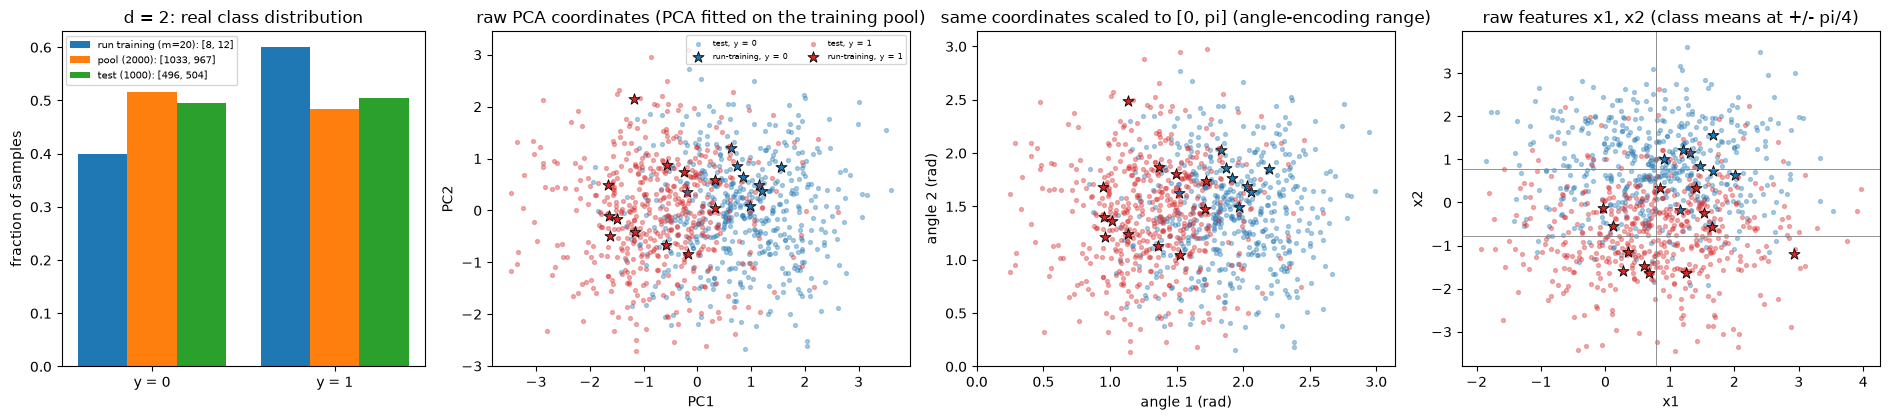

=== data dimension d = 6 ===
training set of a run : X (20, 6)  y (20,) | exploration pool : X (2000, 6) | test set : X (1000, 6)
feature names          : ['x1', 'x2', 'x3', 'x4', 'x5', 'x6'] (real numbers, mean +/- pi/4, unit variance)
original label values  : [0, 1] -> mapped to y_pm = +1 / -1 for the margin loss
class counts           : run-training {np.int64(0): np.int64(8), np.int64(1): np.int64(12)} | pool {np.int64(0): np.int64(1012), np.int64(1): np.int64(988)} | test {np.int64(0): np.int64(474), np.int64(1): np.int64(526)}
class means            : mu_0 = [0.785 0.785 0.785 0.785 0.785 0.785]  mu_1 = [ 0.785  0.785  0.785 -0.785 -0.785 -0.785] | Bayes-optimal accuracy = 0.913


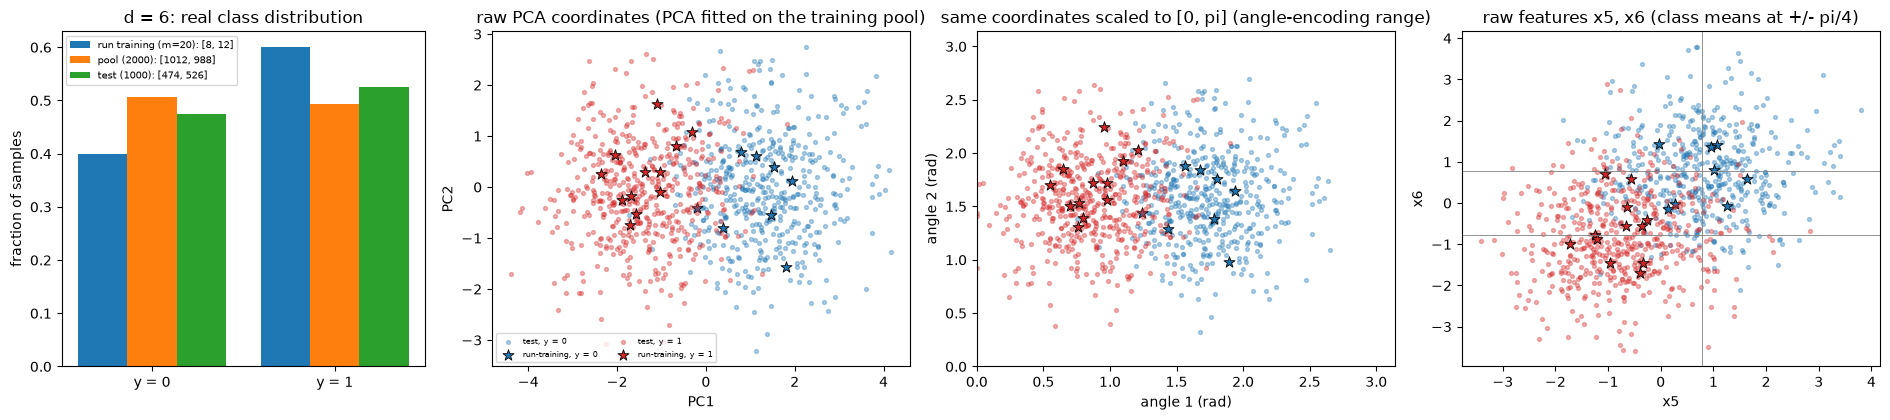

In [5]:
CLASS_NAME = {0: "y = 0 (mean (pi/4) 1)", 1: "y = 1 (mean (pi/4)(1,..,1,-1,..,-1))"}
COL = {0: "#1f77b4", 1: "#d62728"}

def explore_dimension(d, n_pool=2000, n_test=1000, seed=SEED):
    """Draw from the paper's generator, print the facts, return (train pool, test) for the plots."""
    rr = np.random.default_rng(seed + d)
    Xp, yp = draw_data(d, n_pool, rr); Xt, yt = draw_data(d, n_test, rr)
    Xm, ym = draw_data(d, M_TRAIN, np.random.default_rng(SEED))              # the 20-sample training set of a run
    print(f"=== data dimension d = {d} ===")
    print(f"training set of a run : X {Xm.shape}  y {ym.shape} | exploration pool : X {Xp.shape} | test set : X {Xt.shape}")
    print("feature names          :", [f"x{i + 1}" for i in range(d)], "(real numbers, mean +/- pi/4, unit variance)")
    print("original label values  :", sorted(np.unique(yp).tolist()), "-> mapped to y_pm = +1 / -1 for the margin loss")
    print("class counts           : run-training", dict(zip(*np.unique(ym, return_counts=True))), "| pool", dict(zip(*np.unique(yp, return_counts=True))),
          "| test", dict(zip(*np.unique(yt, return_counts=True))))
    mu0, mu1 = class_means(d)
    print("class means            : mu_0 =", np.round(mu0, 3), " mu_1 =", np.round(mu1, 3), f"| Bayes-optimal accuracy = {bayes_accuracy(d):.3f}")
    return (Xp, yp), (Xt, yt), (Xm, ym)

def plot_dimension(d, pool, test, small):
    (Xp, yp), (Xt, yt), (Xm, ym) = pool, test, small
    fig, axs = plt.subplots(1, 4, figsize=(19, 4.3), gridspec_kw=dict(width_ratios=[1, 1.15, 1.15, 1.15]))
    # (a) real class distribution
    ax = axs[0]; w = 0.27
    for k, (name, yy) in enumerate([("run training (m=20)", ym), ("pool (2000)", yp), ("test (1000)", yt)]):
        frac = np.bincount(yy, minlength=2) / len(yy)
        ax.bar(np.arange(2) + (k - 1) * w, frac, w, label=f"{name}: {np.bincount(yy, minlength=2).tolist()}")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["y = 0", "y = 1"]); ax.set_ylabel("fraction of samples"); ax.set_title(f"d = {d}: real class distribution"); ax.legend(fontsize=7)
    # (b) raw 2-D coordinates: PCA fitted on the training pool (for d = 2 these are the two features themselves)
    pca = PCA(n_components=2, random_state=SEED).fit(Xp)
    Zp, Zt, Zm = pca.transform(Xp), pca.transform(Xt), pca.transform(Xm)
    ax = axs[1]
    for c in (0, 1):
        ax.scatter(Zt[yt == c, 0], Zt[yt == c, 1], s=8, alpha=0.35, color=COL[c], label=f"test, {CLASS_NAME[c][:5]}")
        ax.scatter(Zm[ym == c, 0], Zm[ym == c, 1], s=70, marker="*", edgecolor="k", linewidth=0.6, color=COL[c], label=f"run-training, {CLASS_NAME[c][:5]}")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title("raw PCA coordinates (PCA fitted on the training pool)"); ax.legend(fontsize=6, ncol=2)
    # (c) the same coordinates scaled to [0, pi] (the range of rotation angles used by angle encoding), scaler fitted on the training pool, test clipped
    sc = MinMaxScaler((0, np.pi)).fit(Zp)
    At, Am = np.clip(sc.transform(Zt), 0, np.pi), np.clip(sc.transform(Zm), 0, np.pi)
    ax = axs[2]
    for c in (0, 1):
        ax.scatter(At[yt == c, 0], At[yt == c, 1], s=8, alpha=0.35, color=COL[c])
        ax.scatter(Am[ym == c, 0], Am[ym == c, 1], s=70, marker="*", edgecolor="k", linewidth=0.6, color=COL[c])
    ax.set_xlim(0, np.pi); ax.set_ylim(0, np.pi); ax.set_xlabel("angle 1 (rad)"); ax.set_ylabel("angle 2 (rad)"); ax.set_title("same coordinates scaled to [0, pi] (angle-encoding range)")
    # (d) the two most informative raw features: x_{d-1}, x_d are in the half where the class means differ
    ax = axs[3]; j = d - 1 if d > 2 else 1; i = d - 2 if d > 2 else 0
    for c in (0, 1):
        ax.scatter(Xt[yt == c, i], Xt[yt == c, j], s=8, alpha=0.35, color=COL[c]); ax.scatter(Xm[ym == c, i], Xm[ym == c, j], s=70, marker="*", edgecolor="k", linewidth=0.6, color=COL[c])
    ax.axvline(np.pi / 4, color="gray", lw=0.6); ax.axhline(np.pi / 4, color="gray", lw=0.6); ax.axhline(-np.pi / 4, color="gray", lw=0.6)
    ax.set_xlabel(f"x{i + 1}"); ax.set_ylabel(f"x{j + 1}"); ax.set_title(f"raw features x{i + 1}, x{j + 1} (class means at +/- pi/4)")
    plt.tight_layout(); plt.show()

EXPL = {}
for d_show in (2, D_Q):
    EXPL[d_show] = explore_dimension(d_show)
    plot_dimension(d_show, *EXPL[d_show])


## 2. Building blocks: simulator, loss, attacks, models, bounds

**Exact simulator.** To train 10 qubits with gradients on a shared CPU the notebook uses its own differentiable state-vector simulator in torch (single-qubit `Rot` gates as 2x2 matrices, CNOTs as index permutations, `<Z>` read-out from the probabilities). It implements exactly the gates of `qml.StronglyEntanglingLayers` (each layer: `Rot` on every qubit, then `CNOT(i, (i + r) mod n)` with `r = layer mod (n - 1) + 1`) and the two embeddings. Later, in the circuit-drawing section below, we assert that it equals the real PennyLane QNode, for values **and** for the gradients with respect to x that FGSM relies on. Wire 0 is the most significant bit, as in PennyLane.

In [6]:
N_QUBITS_OF = lambda d, emb: d if emb == "angle" else max(1, int(math.ceil(math.log2(d))))

# ---------- exact state-vector simulator (torch, differentiable); wire 0 is the most significant bit as in PennyLane ----------
_PERM, _ZV = {}, {}
def cnot_perm(n, c, t):
    key = (n, c, t)
    if key not in _PERM:
        idx = np.arange(2 ** n); cb = (idx >> (n - 1 - c)) & 1
        _PERM[key] = torch.tensor(idx ^ (cb << (n - 1 - t)), dtype=torch.long)       # CNOT is its own inverse -> gather = apply
    return _PERM[key]

def zvec(n):
    """weights w with  f = sum_b |psi_b|^2 w_b = mean_i <Z_i>."""
    if n not in _ZV:
        idx = np.arange(2 ** n); bits = (idx[:, None] >> (n - 1 - np.arange(n))[None, :]) & 1
        _ZV[n] = torch.tensor((1 - 2 * bits).mean(1), dtype=torch.float32)
    return _ZV[n]

def rot_mats(w):
    """PennyLane qml.Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi) for a tensor w[..., 3] -> complex [..., 2, 2]."""
    phi, th, om = w[..., 0], w[..., 1], w[..., 2]
    c, s = torch.cos(th / 2), torch.sin(th / 2)
    a, b = (phi + om) / 2, (phi - om) / 2
    u00 = torch.complex(torch.cos(a) * c, -torch.sin(a) * c);  u01 = torch.complex(-torch.cos(b) * s, -torch.sin(b) * s)
    u10 = torch.complex(torch.cos(b) * s, -torch.sin(b) * s);  u11 = torch.complex(torch.cos(a) * c, torch.sin(a) * c)
    return torch.stack([torch.stack([u00, u01], -1), torch.stack([u10, u11], -1)], -2).to(CDT)

def apply1(psi, U, q, n):
    B = psi.shape[0]
    return torch.einsum("ij,bajc->baic", U, psi.reshape(B, 2 ** q, 2, 2 ** (n - q - 1))).reshape(B, -1)

def sel_apply(psi, w, n):
    """qml.StronglyEntanglingLayers(w, wires=range(n)): per layer Rot on every qubit, then CNOT(i, (i + r) mod n) with r = l mod (n - 1) + 1."""
    for l in range(w.shape[0]):
        R = rot_mats(w[l])
        for i in range(n):
            psi = apply1(psi, R[i], i, n)
        if n > 1:
            r = l % (n - 1) + 1
            for i in range(n):
                psi = psi[:, cnot_perm(n, i, (i + r) % n)]
    return psi

def embed(X, emb, n):
    """angle: paper U(x) = prod_j exp(-i x_j sigma_Y)  =  RY(2 x_j) on qubit j, applied to |0...0>; amplitude: x padded with zeros and normalised."""
    B = X.shape[0]
    if emb == "angle":
        psi = torch.ones(B, 1)
        for j in range(n):
            v = torch.stack([torch.cos(X[:, j]), torch.sin(X[:, j])], -1)
            psi = (psi[:, :, None] * v[:, None, :]).reshape(B, -1)
        return psi.to(CDT)
    Xp = torch.nn.functional.pad(X, (0, 2 ** n - X.shape[1]))
    return (Xp / Xp.norm(dim=1, keepdim=True)).to(CDT)

def qforward(X, w, emb, n):
    """f(x) = Tr(A rho(x)) with A = V^dagger (mean_i Z_i) V : the classifier score in [-1, 1]."""
    psi = sel_apply(embed(X, emb, n), w, n)
    return (psi.real ** 2 + psi.imag ** 2) @ zvec(n)

# ---------- the same circuits as real PennyLane QNodes (these are the objects that are drawn and used for the equivalence test) ----------
def make_qnode(d, emb, L=N_LAYERS):
    n = N_QUBITS_OF(d, emb)
    dev = qml.device("default.qubit", wires=n)
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(x, w):
        if emb == "angle":
            for j in range(n):
                qml.RY(2 * x[..., j], wires=j)                    # exp(-i x_j sigma_Y) = RY(2 x_j)
        else:
            qml.AmplitudeEmbedding(x, wires=range(n), pad_with=0.0, normalize=True)
        qml.StronglyEntanglingLayers(w, wires=range(n))
        return [qml.expval(qml.PauliZ(i)) for i in range(n)]
    return circuit, n

def qnode_forward(circuit, X, w):
    return torch.stack(circuit(X, w), -1).mean(-1)


**Loss, FGSM, training loop, models and bounds.** `loss_fn` is the paper's logistic loss written with the margin y f. `fgsm_c` is the classical one-step FGSM (the standard approximation of the p = infinity attack). `adam_train` regenerates the attack at the current weights for every mini-batch (the min-max training of the paper). `QModel` is the quantum classifier, `LinModel` a classical linear model on the identical inputs. The bound helpers implement, for r = p = infinity: the constant J(r) of Appendix D (closed form checked against numerical integration), Theorem 2 for pure and for mixed states, Proposition 1 *as printed* (`S_paper`), the **exact** S obtained from the states (`S_exact`), and the PAC bound of Theorem 1 combined with Theorem 3.

In [7]:
# ---------- attacks and risks ----------
def fgsm_c(fwd, X, ypm, eps):
    """Classical FGSM, the standard one-step approximation of the p = infinity attack: x' = x + eps * sign(grad_x loss)."""
    Xa = X.clone().requires_grad_(True)
    g, = torch.autograd.grad(loss_fn(fwd(Xa), ypm).sum(), Xa)
    return (X + eps * g.sign()).detach()

def adam_train(fwd, params, X, ypm, eps, rng, epochs=None, bs=None, lr=None):
    """Adam on the (adversarial if eps > 0) empirical risk; the attack is regenerated at the current weights for every mini-batch."""
    epochs = EPOCHS if epochs is None else epochs; bs = BATCH_SIZE if bs is None else bs; lr = LR if lr is None else lr
    opt = torch.optim.Adam(params, lr=lr); hist = []
    for ep in range(epochs):
        order = rng.permutation(len(X)); tot = 0.0
        for k in range(0, len(X), bs):
            idx = order[k:k + bs]; xb, yb = X[idx], ypm[idx]
            if eps > 0:
                xb = fgsm_c(fwd, xb, yb, eps)
            loss = loss_fn(fwd(xb), yb).mean()
            opt.zero_grad(); loss.backward(); opt.step(); tot += float(loss) * len(idx)
        hist.append(tot / len(X))
    return hist

def risks(fwd, X, ypm, eps, chunk=250):
    """mean loss and accuracy on clean and FGSM-attacked inputs (attack computed against the final weights)."""
    out = dict(clean_loss=0.0, adv_loss=0.0, clean_acc=0.0, adv_acc=0.0); n = len(X)
    for k in range(0, n, chunk):
        xb, yb = X[k:k + chunk], ypm[k:k + chunk]
        xa = fgsm_c(fwd, xb, yb, eps) if eps > 0 else xb
        with torch.no_grad():
            for tag, xx in (("clean", xb), ("adv", xa)):
                f = fwd(xx)
                out[tag + "_loss"] += float(loss_fn(f, yb).sum()); out[tag + "_acc"] += float(((f * yb) > 0).sum())
    return {k: v / n for k, v in out.items()}

# ---------- the quantum and the classical models ----------
class QModel:
    def __init__(self, d, emb, rng, L=N_LAYERS):
        self.d, self.emb, self.n = d, emb, N_QUBITS_OF(d, emb)
        self.w = torch.tensor(rng.normal(0, INIT_SD, (L, self.n, 3)), dtype=torch.float32, requires_grad=True)
    def fwd(self, X): return qforward(X, self.w, self.emb, self.n)
    def params(self): return [self.w]
    def n_params(self): return int(self.w.numel())

class LinModel:
    """classical baseline on the identical inputs: f(x) = w.x + b, same loss, same FGSM, same Adam budget."""
    def __init__(self, d, rng):
        self.w = torch.tensor(rng.normal(0, 0.1, d), dtype=torch.float32, requires_grad=True)
        self.b = torch.zeros(1, requires_grad=True)
    def fwd(self, X): return X @ self.w + self.b
    def params(self): return [self.w, self.b]
    def n_params(self): return int(self.w.numel() + 1)

# ---------- the bounds of the paper ----------
def J_inf():
    """J(r) for r = infinity: 36 * 2^(1/r) * int_0^a sqrt(ln(1/u)) du with a = 2^(-1/r)/6 (end of Appendix D); closed form checked by quadrature."""
    a = 1 / 6
    closed = 36 * (a * math.sqrt(math.log(1 / a)) + math.sqrt(math.pi) / 2 * special.erfc(math.sqrt(math.log(1 / a))))
    quad = 36 * integrate.quad(lambda u: math.sqrt(math.log(1 / u)), 0, a)[0]
    assert abs(closed - quad) < 1e-6
    return closed
J_R_INF = J_inf()

def rc_thm2_pure(psi, b=B_OBS):
    """Theorem 2, r = infinity, pure states: R(F) <= (b/m) * || sqrt(sum_i rho_i^2) ||_1 = (b/m) * sum_k sqrt(lambda_k(Gram)), Gram_ij = <psi_i|psi_j>."""
    P = psi.numpy().astype(np.complex128)
    ev = np.clip(np.linalg.eigvalsh(P.conj() @ P.T), 0, None)
    return float(b * np.sqrt(ev).sum() / len(P))

def rc_thm2_density(rhos, b=B_OBS):
    """Theorem 2, r = infinity, general states: (b/m) * || sqrt(sum_i rho_i^2) ||_1  (dense dH x dH matrices)."""
    M = sum(r @ r for r in rhos)
    ev = np.clip(np.linalg.eigvalsh((M + M.conj().T) / 2), 0, None)
    return float(b * np.sqrt(ev).sum() / len(rhos))

def S_paper(emb, d, eps, Xtr, L=1):
    """Proposition 1 as printed, p = infinity (S includes the factor dH): angle 2L(2 eps)^d ; amplitude 2^(1+ceil(log2 d)) min{eps max(1, d^(1/2)) / min ||x||, 1}.
    CHOICE: min_x ||x|| is taken over the training sample (over all of R^d it is 0 and the amplitude term is 2 dH)."""
    if emb == "angle":
        return 2 * L * (2 * eps) ** d
    return 2.0 ** (1 + math.ceil(math.log2(d))) * min(eps * max(1.0, d ** 0.5) / float(np.linalg.norm(Xtr, axis=1).min()), 1.0)

def S_exact(emb, d, eps, Xtr):
    """S^C = dH * sup_{||x - x'||_inf <= eps} || rho(x) - rho(x') ||_1 = dH * 2 sqrt(1 - |<psi(x)|psi(x')>|^2), evaluated exactly.
    angle (L = 1): <psi(x)|psi(x + delta)> = prod_j cos(delta_j) -> worst case delta_j = eps. amplitude: the angle between x and x + delta is quasi-convex in delta,
    so its maximum over the box is attained at a vertex delta in {-eps, +eps}^d; all 2^d vertices are enumerated for every training sample."""
    n = N_QUBITS_OF(d, emb); dH = 2 ** n
    if emb == "angle":
        return dH * 2 * math.sqrt(1 - math.cos(eps) ** (2 * d))
    V = np.array(np.meshgrid(*[[-eps, eps]] * d)).reshape(d, -1).T            # 2^d x d
    best = 0.0
    for x in Xtr.astype(np.float64):
        xp = x[None, :] + V
        c2 = (xp @ x) ** 2 / ((xp ** 2).sum(1) * (x @ x))
        best = max(best, float(2 * np.sqrt(np.clip(1 - c2, 0, None)).max()))
    return dH * best

def pac_terms(R, S, m, delta=DELTA, b=B_OBS):
    """returns (conventional bound, adversarial bound) on the generalisation error: 2 eta (R [+ b S J / sqrt(m)]) + 3 B sqrt(ln(2/delta)/(2m)), eta = alpha/4, B = 1."""
    eta = ALPHA_LOSS / 4.0; conf = 3 * 1.0 * math.sqrt(math.log(2 / delta) / (2 * m))
    return 2 * eta * R + conf, 2 * eta * (R + b * S * J_R_INF / math.sqrt(m)) + conf


**One repetition of experiment A** (`run_once`): draw m training and 1000 test samples, adversarially train the quantum classifier (FGSM, 40 epochs), measure the training and test loss on clean and attacked inputs (the attack is recomputed against the final weights), and evaluate the bounds on that training sample. The same function also trains the classical linear baseline and fits a random forest and an RBF-SVC on the identical samples.

In [8]:
def run_once(d, emb, seed, m=M_TRAIN, eps=EPS_C, with_baselines=True):
    """One repetition: draw m training and M_TEST test samples, adversarially train the quantum classifier (and the linear baseline),
    measure conventional and adversarial generalisation errors, evaluate the bounds of the paper."""
    rng = np.random.default_rng(10_000 * seed + 100 * d + (0 if emb == "angle" else 1) + m)
    torch.manual_seed(int(rng.integers(1 << 30)))
    Xtr, ytr = draw_data(d, m, rng); Xte, yte = draw_data(d, M_TEST, rng)
    Xtr_t, Xte_t, ptr, pte = torch.tensor(Xtr), torch.tensor(Xte), to_pm(ytr), to_pm(yte)
    row = dict(d=d, emb=emb, seed=seed, m=m)
    t0 = time.time()
    model = QModel(d, emb, rng)
    hist = adam_train(model.fwd, model.params(), Xtr_t, ptr, eps, rng)
    rtr = risks(model.fwd, Xtr_t, ptr, eps); rte = risks(model.fwd, Xte_t, pte, eps)
    row.update(train_clean=rtr["clean_loss"], train_adv=rtr["adv_loss"], test_clean=rte["clean_loss"], test_adv=rte["adv_loss"],
               acc_train_clean=rtr["clean_acc"], acc_train_adv=rtr["adv_acc"], acc_test_clean=rte["clean_acc"], acc_test_adv=rte["adv_acc"],
               G_conv=rte["clean_loss"] - rtr["clean_loss"], G_adv=rte["adv_loss"] - rtr["adv_loss"], final_train_loss=hist[-1], q_time=time.time() - t0)
    # --- the bounds of the paper (evaluated on this training sample) ---
    with torch.no_grad():
        psi = embed(Xtr_t, emb, model.n)
    R = rc_thm2_pure(psi)
    for tag, S in (("paper", S_paper(emb, d, eps, Xtr)), ("exact", S_exact(emb, d, eps, Xtr))):
        bc, ba = pac_terms(R, S, m)
        row.update({f"S_{tag}": S, f"excess_rc_{tag}": B_OBS * S * J_R_INF / math.sqrt(m), f"bound_adv_{tag}": ba})
    row.update(R_thm2=R, bound_conv=bc)
    if with_baselines:
        lin = LinModel(d, rng)
        adam_train(lin.fwd, lin.params(), Xtr_t, ptr, eps, rng)
        ltr = risks(lin.fwd, Xtr_t, ptr, eps); lte = risks(lin.fwd, Xte_t, pte, eps)
        row.update(lin_G_conv=lte["clean_loss"] - ltr["clean_loss"], lin_G_adv=lte["adv_loss"] - ltr["adv_loss"],
                   lin_acc_test_clean=lte["clean_acc"], lin_acc_test_adv=lte["adv_acc"])
        rf = RandomForestClassifier(n_estimators=100, random_state=SEED).fit(Xtr, ytr)
        sv = SVC(kernel="rbf", C=1.0).fit(Xtr, ytr)
        row.update(rf_acc_test=float((rf.predict(Xte) == yte).mean()), svc_acc_test=float((sv.predict(Xte) == yte).mean()))
    return row


**The quantum attack of Section VII B.** The embedded state is perturbed by a parametrised unitary `U_theta` (here one `Rot` on every qubit); Algorithm 1 of Appendix H (quantum FGSM) sets `theta = alpha sign(grad_theta loss)` at `theta = 0` and halves it until the Schatten-infinity (operator-norm) distance `||rho - U_theta rho U_theta^dagger||` is below eps. The classifier acts on density matrices, `f = Tr(A rho)` with `A = V^dagger (mean Z) V`; noisy states are mixed states, so everything below is done with 8 x 8 density matrices (3 qubits, dH = 8). The helper `run_quantum_attack` trains on m = 20 states against the attacker of strength 0.001 and then measures conventional and adversarial generalisation errors for every eps of the grid together with the bounds of Theorems 2, 3 and 4.

In [9]:
N_Q = N_QUBITS_OF(D_Q, "amp"); DH = 2 ** N_Q
MIX = LAMBDA_MIN * DH                       # weight of the depolarising channel: rho' = (1 - lambda_min dH) rho + lambda_min I

def sel_unitary(w, n=N_Q):
    """the variational unitary V of the classifier (columns V|k>), so that the observable is A = V^dagger (mean Z) V."""
    return sel_apply(torch.eye(2 ** n, dtype=CDT), w, n).T

def density(X):
    psi = embed(X, "amp", N_Q)
    return psi[:, :, None] * psi.conj()[:, None, :]

def noisy_density(rho):
    return (1 - MIX) * rho + LAMBDA_MIN * torch.eye(DH, dtype=CDT)[None]

def f_rho(rho, w):
    """f = Tr(A rho) = sum_k z_k (V rho V^dagger)_kk."""
    V = sel_unitary(w)
    sig = V[None] @ rho @ V.conj().T[None]
    return torch.einsum("bkk,k->b", sig, zvec(N_Q).to(CDT)).real

def local_unitary(theta):
    """W(theta) = tensor product over qubits of Rot(theta_q): the adversary's parametrised channel U_theta (theta = 0 is the identity)."""
    R = rot_mats(theta); W = R[:, 0]
    for q in range(1, N_Q):
        W = torch.einsum("bij,bkl->bikjl", W, R[:, q]).reshape(W.shape[0], W.shape[1] * 2, W.shape[2] * 2)
    return W

def attack_state(rho, theta):
    W = local_unitary(theta)
    return W @ rho @ W.conj().transpose(1, 2)

def opnorm(M):
    """p = infinity Schatten norm of a batch of Hermitian matrices."""
    return torch.linalg.eigvalsh(M).abs().max(1).values

def qfgsm(rho, ypm, w, eps, alpha=QFGSM_ALPHA, max_iter=QFGSM_MAX_ITER):
    """Algorithm 1 (quantum FGSM, Appendix H): theta <- alpha sign(grad_theta loss) at theta_0 = 0; halve theta while ||rho - U_theta(rho)||_inf >= eps; give up (theta_0) after max_iter."""
    th0 = torch.zeros(rho.shape[0], N_Q, 3, requires_grad=True)
    g, = torch.autograd.grad(loss_fn(f_rho(attack_state(rho, th0), w), ypm).sum(), th0)
    th = (alpha * g.sign()).detach()
    for it in range(max_iter):
        bad = opnorm(rho - attack_state(rho, th)) >= eps
        if not bool(bad.any()):
            break
        th[bad] = th[bad] / 2
    bad = opnorm(rho - attack_state(rho, th)) >= eps
    th[bad] = 0.0
    return attack_state(rho, th).detach()

def q_train(rho, ypm, rng, eps=EPS_Q_TRAIN):
    w = torch.tensor(rng.normal(0, INIT_SD, (N_LAYERS, N_Q, 3)), dtype=torch.float32, requires_grad=True)
    opt = torch.optim.Adam([w], lr=LR)
    for ep in range(EPOCHS):
        order = rng.permutation(len(rho))
        for k in range(0, len(rho), BATCH_SIZE):
            idx = order[k:k + BATCH_SIZE]
            ra = qfgsm(rho[idx], ypm[idx], w, eps)
            loss = loss_fn(f_rho(ra, w), ypm[idx]).mean()
            opt.zero_grad(); loss.backward(); opt.step()
    return w

def q_risk(rho, ypm, w, eps, chunk=500):
    cl = ad = 0.0
    for k in range(0, len(rho), chunk):
        r, y = rho[k:k + chunk], ypm[k:k + chunk]
        ra = qfgsm(r, y, w, eps)
        with torch.no_grad():
            cl += float(loss_fn(f_rho(r, w), y).sum()); ad += float(loss_fn(f_rho(ra, w), y).sum())
    return cl / len(rho), ad / len(rho)

def run_quantum_attack(seed, noisy):
    """Section VII B: train on m = 20 states (noiseless or noisy embedding) against the quantum FGSM adversary of strength 0.001,
    then measure conventional and adversarial generalisation errors for every attack strength eps of the grid, plus the bounds of Theorems 2-4."""
    rng = np.random.default_rng(777 + 31 * seed)      # same data and initial weights for the noiseless and the noisy run of a seed (paired comparison)
    torch.manual_seed(int(rng.integers(1 << 30)))
    Xtr, ytr = draw_data(D_Q, M_TRAIN, rng); Xte, yte = draw_data(D_Q, M_TEST, rng)
    rtr, rte = density(torch.tensor(Xtr)), density(torch.tensor(Xte))
    if noisy:
        rtr, rte = noisy_density(rtr), noisy_density(rte)
    ptr, pte = to_pm(ytr), to_pm(yte)
    w = q_train(rtr, ptr, rng)
    R = rc_thm2_density([r.numpy().astype(np.complex128) for r in rtr])
    rows = []
    for eps in EPS_Q_GRID:
        c_tr, a_tr = q_risk(rtr, ptr, w, eps); c_te, a_te = q_risk(rte, pte, w, eps)
        S3 = eps * max(DH, DH ** 2)                                  # Theorem 3, quantum attack, r = p = infinity: S^Q <= eps max{dH, dH^(2 - 1/r - 1/p)}
        bc, b3 = pac_terms(R, S3, M_TRAIN)
        b4 = pac_terms(R + B_OBS * eps * max(1, DH) / math.sqrt(M_TRAIN), 0.0, M_TRAIN)[0]   # Theorem 4: excess term b eps max{1, dH^(1-1/p-1/r)}/sqrt(m) = b eps dH/sqrt(m), no J factor
        rows.append(dict(seed=seed, noisy=noisy, eps=eps, G_conv=c_te - c_tr, G_adv=a_te - a_tr, train_clean=c_tr, train_adv=a_tr, test_clean=c_te, test_adv=a_te,
                         R_thm2=R, bound_conv=bc, bound_adv_thm3=b3, bound_adv_thm4=b4))
    return rows


## Quantum Circuit Architecture

Three distinct circuits are trained or evaluated, all drawn here from the **real PennyLane QNodes** that the simulator is asserted to match:

1. **Angle embedding** (`RY(2 x_j)` on every qubit, equal to the paper's `exp(-i x_j sigma_Y)`), followed by four `StronglyEntanglingLayers`, read-out `<Z_i>` on every qubit (the score is their mean). n = d qubits (drawn for d = 4).
2. **Amplitude embedding** of the zero-padded, normalised x, followed by the same four layers. n = ceil(log2 d) qubits (drawn for d = 6: 3 qubits, 8 amplitudes, two of them padded zeros).
3. **Quantum-attack circuit** of Section VII B: the embedded density matrix (`QubitDensityMatrix`), the adversarial unitary `U_theta` (one `Rot` per qubit, set by quantum FGSM), then the classifier of architecture 2.

Assumptions where the paper omits details: the two-qubit gate and the entangling ranges of the "strongly entangling layers" are PennyLane's defaults (CNOT, range `l mod (n-1) + 1`), which is what the paper cites; the way the n Pauli-Z outputs are combined into one score is the mean (b = 1); the adversary's circuit `U_theta` is a layer of general single-qubit rotations (Appendix H does not specify it); the angle embedding is applied once (L = 1, no data re-uploading). For each architecture the figure is shown twice: with the templates as boxes and decomposed into the gates that are executed. The equivalence table proves that the numbers produced later come from these very circuits.

,architecture,max |f_simulator - f_PennyLane|,max |grad_x difference|
0,"angle embedding, d = 4 (4 qubits)",6.857590e-08,7.450581e-08
1,"amp embedding, d = 6 (3 qubits)",6.457170e-08,1.043081e-07
2,"quantum-attack circuit, noiseless state (3 qubits, mixed-state QNode)",8.940697e-08,NaN
3,"quantum-attack circuit, noisy (global depolarising) state (3 qubits, mixed-state QNode)",5.960464e-08,NaN


All simulator/QNode equivalence assertions passed: the numbers in this notebook come from circuits that are identical to the drawn QNodes.
Architecture 1 - angle embedding RY(2 x_j), d = 4, 4 qubits, 4 strongly entangling layers: qubits = 4, depth = 18, gates = 36, trainable parameters = 48


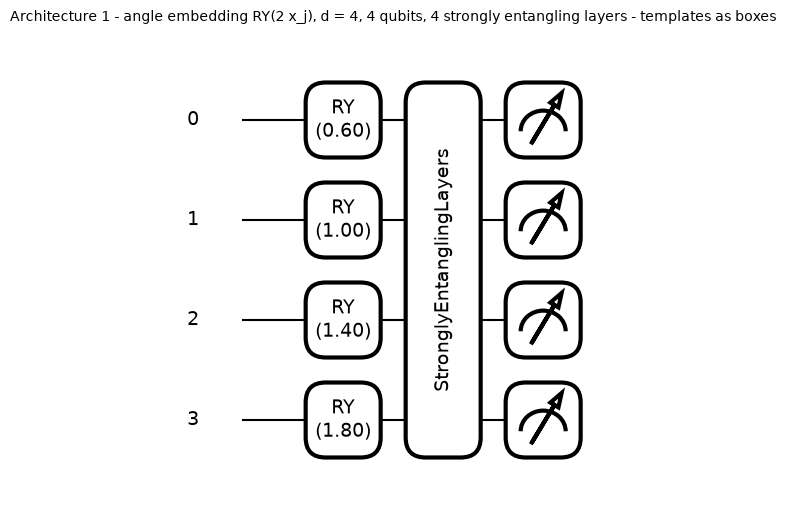

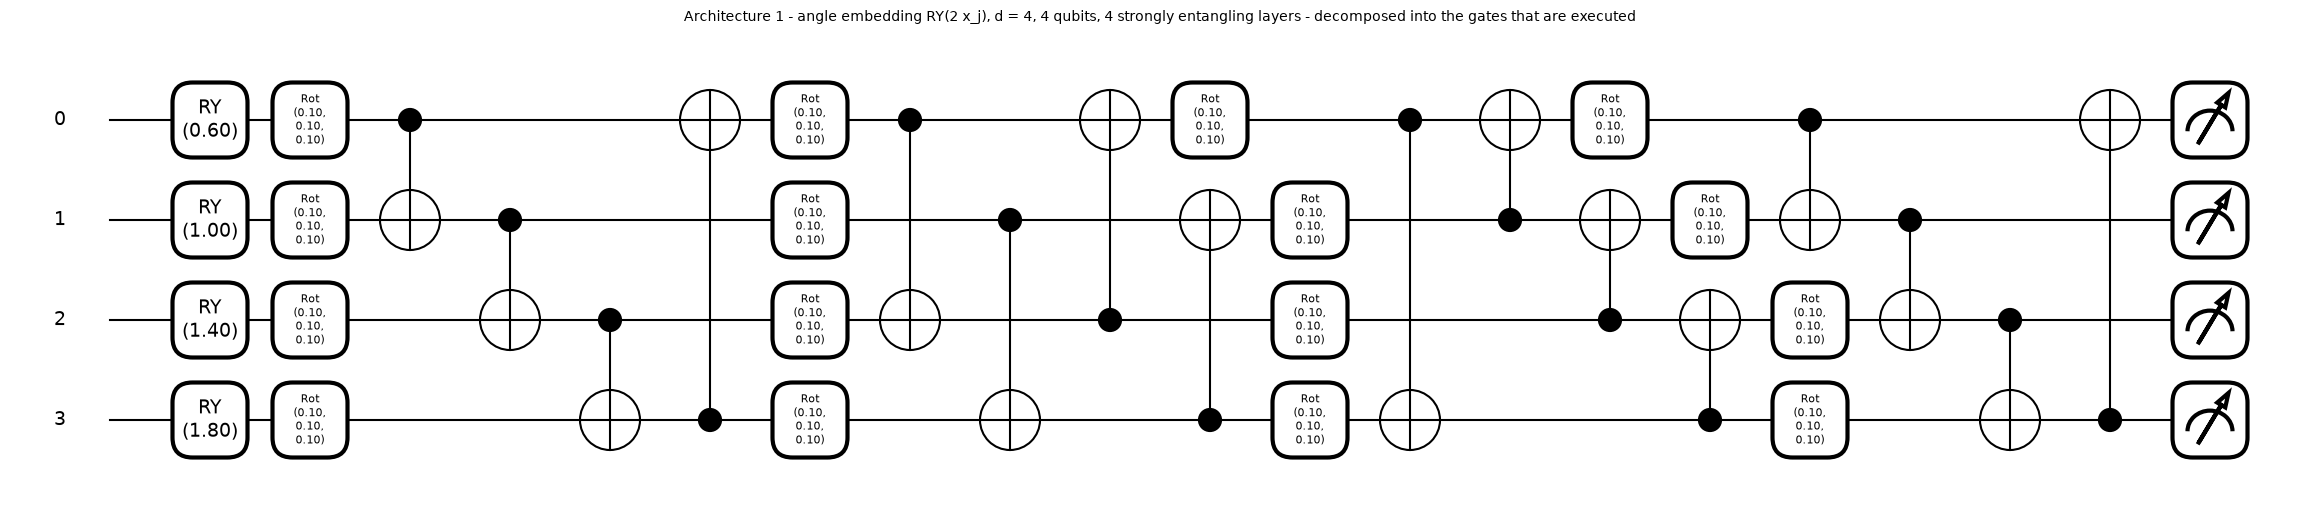

Architecture 2 - amplitude embedding, d = 6 (padded to 8 amplitudes), 3 qubits, 4 strongly entangling layers: qubits = 3, depth = 17, gates = 25, trainable parameters = 36


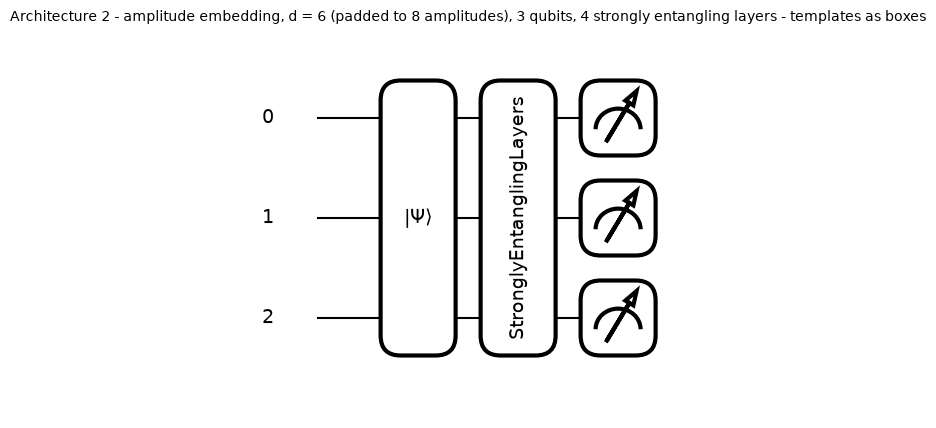

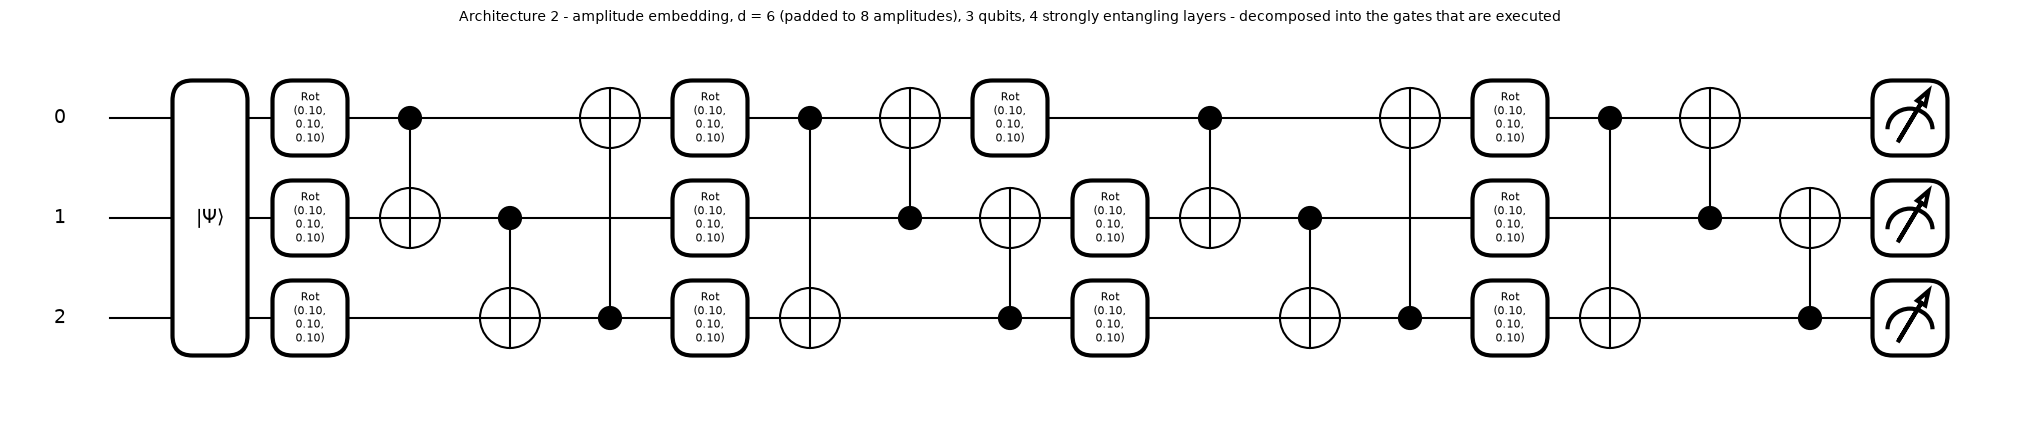

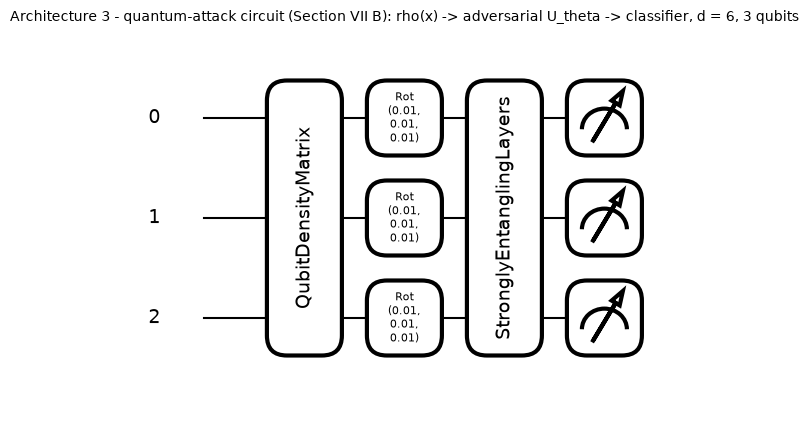

Architecture 3: qubits = 3, trainable classifier parameters = 36, adversary parameters (not trained, set by quantum FGSM) = 9; depth of the classifier part = 4 layers x (1 Rot layer + 3 CNOTs)
The classical-attack circuits of Architectures 1 and 2 have the same variational block; the embedding is the only difference (paper Fig. 2: n = d qubits for rotation embedding, n = ceil(log2 d) for amplitude embedding).


In [10]:
# ---- the quantum-attack circuit of Section VII B as a real PennyLane QNode (mixed-state simulator): embedded state -> adversary U_theta -> classifier ----
dev_B = qml.device("default.mixed", wires=N_Q)
@qml.qnode(dev_B)
def qnode_B(rho, theta, w):
    qml.QubitDensityMatrix(rho, wires=range(N_Q))                  # the (noiseless or noisy) embedded state rho(x)
    for q in range(N_Q):                                            # adversarial channel U_theta (Appendix H); theta = 0 is the identity
        qml.Rot(theta[q, 0], theta[q, 1], theta[q, 2], wires=q)
    qml.StronglyEntanglingLayers(w, wires=range(N_Q))               # classifier
    return [qml.expval(qml.PauliZ(i)) for i in range(N_Q)]

# ---- equivalence of the fast simulator and the PennyLane QNodes (values AND input gradients, which FGSM uses) ----
rr = np.random.default_rng(123)
EQ = []
for emb, d in (("angle", 4), ("amp", 6)):
    circ, n = make_qnode(d, emb)
    X = torch.tensor(rr.normal(0.4, 1.0, (6, d)), dtype=torch.float32, requires_grad=True)
    w = torch.tensor(rr.normal(0, 1.0, (N_LAYERS, n, 3)), dtype=torch.float32)
    f_sim = qforward(X, w, emb, n); g_sim, = torch.autograd.grad(f_sim.sum(), X)
    f_pl = qnode_forward(circ, X, w); g_pl, = torch.autograd.grad(f_pl.sum(), X)
    dv, dg = float((f_sim - f_pl).abs().max()), float((g_sim - g_pl).abs().max())
    assert dv < 1e-5 and dg < 1e-4, (emb, dv, dg)
    EQ.append((f"{emb} embedding, d = {d} ({n} qubits)", dv, dg))
X = torch.tensor(rr.normal(0.4, 1.0, (3, D_Q)), dtype=torch.float32); w = torch.tensor(rr.normal(0, 1.0, (N_LAYERS, N_Q, 3)), dtype=torch.float32)
th = torch.tensor(rr.normal(0, 0.4, (3, N_Q, 3)), dtype=torch.float32)
for name, r in (("noiseless", density(X)), ("noisy (global depolarising)", noisy_density(density(X)))):
    f_sim = f_rho(attack_state(r, th), w)
    f_pl = torch.tensor([float(np.mean(qnode_B(r[i].numpy().astype(np.complex128), th[i].numpy(), w.numpy()))) for i in range(3)])
    dv = float((f_sim - f_pl).abs().max()); assert dv < 1e-5, (name, dv)
    EQ.append((f"quantum-attack circuit, {name} state ({N_Q} qubits, mixed-state QNode)", dv, float("nan")))
display(pd.DataFrame(EQ, columns=["architecture", "max |f_simulator - f_PennyLane|", "max |grad_x difference|"]))
print("All simulator/QNode equivalence assertions passed: the numbers in this notebook come from circuits that are identical to the drawn QNodes.")

# ---- drawings and resource counts, one per distinct architecture ----
def describe(circ, args, title, n_params):
    specs = qml.specs(circ, level="device")(*args)
    res = specs.resources
    print(f"{title}: qubits = {specs.num_device_wires}, depth = {res.depth}, gates = {res.num_gates}, trainable parameters = {n_params}")
    for level, sub in (("top", "templates as boxes"), ("device", "decomposed into the gates that are executed")):
        fig, ax = qml.draw_mpl(circ, level=level, decimals=2)(*args)
        fig.suptitle(f"{title} - {sub}", fontsize=10, y=1.02); plt.show()

ARCH = {}
circ, n = make_qnode(4, "angle"); w0 = torch.zeros(N_LAYERS, n, 3) + 0.1
describe(circ, (torch.tensor([0.3, 0.5, 0.7, 0.9]), w0), "Architecture 1 - angle embedding RY(2 x_j), d = 4, 4 qubits, 4 strongly entangling layers", int(w0.numel()))
circ, n = make_qnode(D_Q, "amp"); w0 = torch.zeros(N_LAYERS, n, 3) + 0.1
describe(circ, (torch.tensor([0.3, 0.5, 0.7, 0.9, 1.1, 1.3]), w0), "Architecture 2 - amplitude embedding, d = 6 (padded to 8 amplitudes), 3 qubits, 4 strongly entangling layers", int(w0.numel()))
rho0 = density(torch.tensor([[0.3, 0.5, 0.7, 0.9, 1.1, 1.3]]))[0].numpy().astype(np.complex128); th0 = np.full((N_Q, 3), 0.01); w0n = np.zeros((N_LAYERS, N_Q, 3)) + 0.1
fig, ax = qml.draw_mpl(qnode_B, level="top", decimals=2)(rho0, th0, w0n); fig.suptitle("Architecture 3 - quantum-attack circuit (Section VII B): rho(x) -> adversarial U_theta -> classifier, d = 6, 3 qubits", fontsize=10, y=1.02); plt.show()
print(f"Architecture 3: qubits = {N_Q}, trainable classifier parameters = {w0n.size}, adversary parameters (not trained, set by quantum FGSM) = {th0.size}; "
      f"depth of the classifier part = 4 layers x (1 Rot layer + {N_Q} CNOTs)")
print("The classical-attack circuits of Architectures 1 and 2 have the same variational block; the embedding is the only difference "
      "(paper Fig. 2: n = d qubits for rotation embedding, n = ceil(log2 d) for amplitude embedding).")


## 3. Checking the pieces of the bound

Before comparing bounds with measurements we test the analytic ingredients. (a) `J(infinity)` of Appendix D. (b) For the angle embedding, `S = dH sup ||rho(x) - rho(x')||_1` has an exact closed form: the overlap of two product states is `prod_j cos(delta_j)`, so the worst perturbation moves every angle by eps, giving a trace distance `2 sqrt(1 - cos(eps)^(2d))`. The cell reproduces this trace distance with the simulated states and compares it with what Proposition 1 prints, `S = 2L (2 eps)^d`. (c) For amplitude embedding the exact value is obtained by enumerating all `2^d` vertices of the l_infinity ball (the angle between x and x + delta is a quasi-convex function of delta, so its maximum on the box sits at a vertex) for every training sample.

In [11]:
print(f"J(r = infinity) = {J_R_INF:.4f}   (closed form of Appendix D checked against numerical quadrature)")

# (1) the exact S for the angle embedding is a trace distance that the simulator itself reproduces
rows = []
for d in D_LIST:
    n = d
    x = torch.tensor(np.random.default_rng(d).normal(0.4, 1.0, (1, d)), dtype=torch.float32)
    xp = x + EPS_C * torch.ones_like(x)                                     # worst-case perturbation: every angle moved by +eps
    p0, p1 = embed(x, "angle", n)[0], embed(xp, "angle", n)[0]
    ov = float((p0.conj() @ p1).abs() ** 2)
    td = 2 * math.sqrt(max(0.0, 1 - ov))                                    # || |p0><p0| - |p1><p1| ||_1 for pure states
    closed = 2 * math.sqrt(1 - math.cos(EPS_C) ** (2 * d))
    assert abs(td - closed) < 1e-4, (d, td, closed)
    Sp = S_paper("angle", d, EPS_C, None); Se = S_exact("angle", d, EPS_C, None)
    rows.append(dict(d=d, dH=2 ** d, **{"trace dist. printed (2 eps^d)": 2 * EPS_C ** d, "trace dist. exact (simulator)": td,
                                       "S printed (Prop. 1)": Sp, "S exact": Se, "printed is a valid upper bound": Sp >= Se}))
display(pd.DataFrame(rows).round(4))
print("Reading: for the angle embedding the printed Proposition 1 gives S = 2 (2 eps)^d, which shrinks with d, but the exact value dH * 2 sqrt(1 - cos(eps)^(2d)) grows like 2^d.")
print("The proof in Appendix E bounds the diamond distance of a TENSOR PRODUCT of single-qubit rotations by a PRODUCT of the single-qubit distances; a product of differences is not the difference of products.")

# (2) the amplitude formula is an upper bound on the exact value (training samples of one run)
rows = []
for d in D_LIST:
    Xa, _ = draw_data(d, M_TRAIN, np.random.default_rng(d))
    Sp, Se = S_paper("amp", d, EPS_C, Xa), S_exact("amp", d, EPS_C, Xa)
    rows.append(dict(d=d, qubits=N_QUBITS_OF(d, "amp"), dH=2 ** N_QUBITS_OF(d, "amp"), **{"S printed (Prop. 1)": Sp, "S exact": Se, "printed is a valid upper bound": Sp >= Se - 1e-9}))
display(pd.DataFrame(rows).round(4))


J(r = infinity) = 9.8932   (closed form of Appendix D checked against numerical quadrature)


,d,dH,trace dist. printed (2 eps^d),trace dist. exact (simulator),S printed (Prop. 1),S exact,printed is a valid upper bound
0,2,4,0.1800,0.8174,0.7200,3.2696,False
1,4,16,0.0162,1.1067,0.2592,17.7065,False
2,6,64,0.0015,1.2993,0.0933,83.1575,False
3,8,256,0.0001,1.4403,0.0336,368.7128,False
4,10,1024,0.0000,1.5479,0.0121,1585.0723,False


Reading: for the angle embedding the printed Proposition 1 gives S = 2 (2 eps)^d, which shrinks with d, but the exact value dH * 2 sqrt(1 - cos(eps)^(2d)) grows like 2^d.
The proof in Appendix E bounds the diamond distance of a TENSOR PRODUCT of single-qubit rotations by a PRODUCT of the single-qubit distances; a product of differences is not the difference of products.


,d,qubits,dH,S printed (Prop. 1),S exact,printed is a valid upper bound
0,2,1,2,3.7165,3.5560,True
1,4,2,4,8.0000,7.9833,True
2,6,3,8,7.3417,7.3405,True
3,8,3,8,5.9081,5.9081,True
4,10,4,16,11.6643,11.6643,True


## 4. Experiment A: classical FGSM attacks (paper Figs. 4 and 5)

For every data dimension d and both embeddings, `N_SEEDS` independent repetitions of: draw 20 + 1000 samples, adversarially train for 40 epochs with FGSM at eps = 0.3, measure the **conventional generalisation error** (clean test loss minus clean training loss) and the **adversarial generalisation error** (loss on attacked test inputs minus loss on attacked training inputs). The tables show means; the four-panel figures further down show mean and standard deviation, the difference of the two errors (the quantity that the paper says converges or diverges), the excess-Rademacher-complexity term of Theorem 3 with S from Proposition 1 and with S exact, and the full PAC bounds against the measured error.

In [12]:
t_run = time.time(); ROWS = []
for d in D_LIST:
    for emb in ("angle", "amp"):
        t1 = time.time()
        for s in range(N_SEEDS):
            ROWS.append(run_once(d, emb, s))
        r = pd.DataFrame([x for x in ROWS if x["d"] == d and x["emb"] == emb])
        print(f"d = {d:2d} {emb:5s}: G_conv = {r.G_conv.mean():+.3f}, G_adv = {r.G_adv.mean():+.3f}  ({time.time() - t1:5.1f} s for {N_SEEDS} seeds)", flush=True)
RES = pd.DataFrame(ROWS)
print(f"total {time.time() - t_run:.0f} s")
agg = RES.groupby(["emb", "d"]).agg(
    qubits=("d", lambda s: N_QUBITS_OF(int(s.iloc[0]), RES.loc[s.index[0], "emb"])),
    train_clean=("train_clean", "mean"), test_clean=("test_clean", "mean"), train_adv=("train_adv", "mean"), test_adv=("test_adv", "mean"),
    G_conv=("G_conv", "mean"), G_conv_sd=("G_conv", "std"), G_adv=("G_adv", "mean"), G_adv_sd=("G_adv", "std"),
    acc_clean=("acc_test_clean", "mean"), acc_adv=("acc_test_adv", "mean")).round(3)
agg["gap"] = (agg.G_adv - agg.G_conv).round(3)
display(agg)


d =  2 angle: G_conv = +0.107, G_adv = +0.181  ( 87.8 s for 8 seeds)


d =  2 amp  : G_conv = +0.069, G_adv = +0.096  ( 48.4 s for 8 seeds)


d =  4 angle: G_conv = +0.268, G_adv = +0.340  ( 92.7 s for 8 seeds)


d =  4 amp  : G_conv = +0.135, G_adv = +0.207  ( 56.1 s for 8 seeds)


d =  6 angle: G_conv = +0.190, G_adv = +0.193  (132.4 s for 8 seeds)


...

d =  8 amp  : G_conv = +0.158, G_adv = +0.266  ( 52.0 s for 8 seeds)


d = 10 angle: G_conv = +0.040, G_adv = +0.030  (387.4 s for 8 seeds)


d = 10 amp  : G_conv = +0.150, G_adv = +0.259  ( 74.2 s for 8 seeds)


total 1386 s


qubits  train_clean  test_clean  train_adv  test_adv  G_conv  G_conv_sd  G_adv  G_adv_sd  acc_clean  acc_adv    gap
emb   d                                                                                                                      
amp   2        1        0.316       0.385      0.455     0.551   0.069      0.109  0.096     0.110      0.617    0.450  0.027
      4        2        0.216       0.350      0.347     0.554   0.135      0.082  0.207     0.083      0.666    0.446  0.072
      6        3        0.097       0.274      0.227     0.491   0.178      0.050  0.265     0.067      0.760    0.514  0.087
      8        3        0.073       0.231      0.204     0.470   0.158      0.031  0.266     0.068      0.814    0.541  0.108
      10       4        0.090       0.240      0.201     0.460   0.150      0.039  0.259     0.046      0.836    0.558  0.109
angle 2        2        0.365       0.472      0.510     0.691   0.107      0.074  0.181     0.075      0.528    0.306  0.074
      4        4        0.213       0.481      0.394     0.734   0.268      0.048  0.340     0.029      0.525    0.149  0.072
      6        6        0.305       0.495      0.454     0.647   0.190      0.033  0.193     0.031      0.513    0.094  0.003
      8        8        0.390       0.500      0.491     0.583   0.110      0.029  0.092     0.026      0.505    0.071 -0.018
      10      10        0.460       0.500      0.507     0.537   0.040      0.010  0.030     0.009      0.495    0.060 -0.010

**Reading the figures.** Panel 1 is the analogue of the top rows of Figs. 4 and 5, panel 2 isolates the gap between the two errors, panels 3 and 4 correspond to the bottom rows (bounds). The dashed grey curve in panel 2 is the same gap for an adversarially trained classical linear model on identical inputs, which is not covered by the paper's theory but shows what a classical model does in the same experiment.

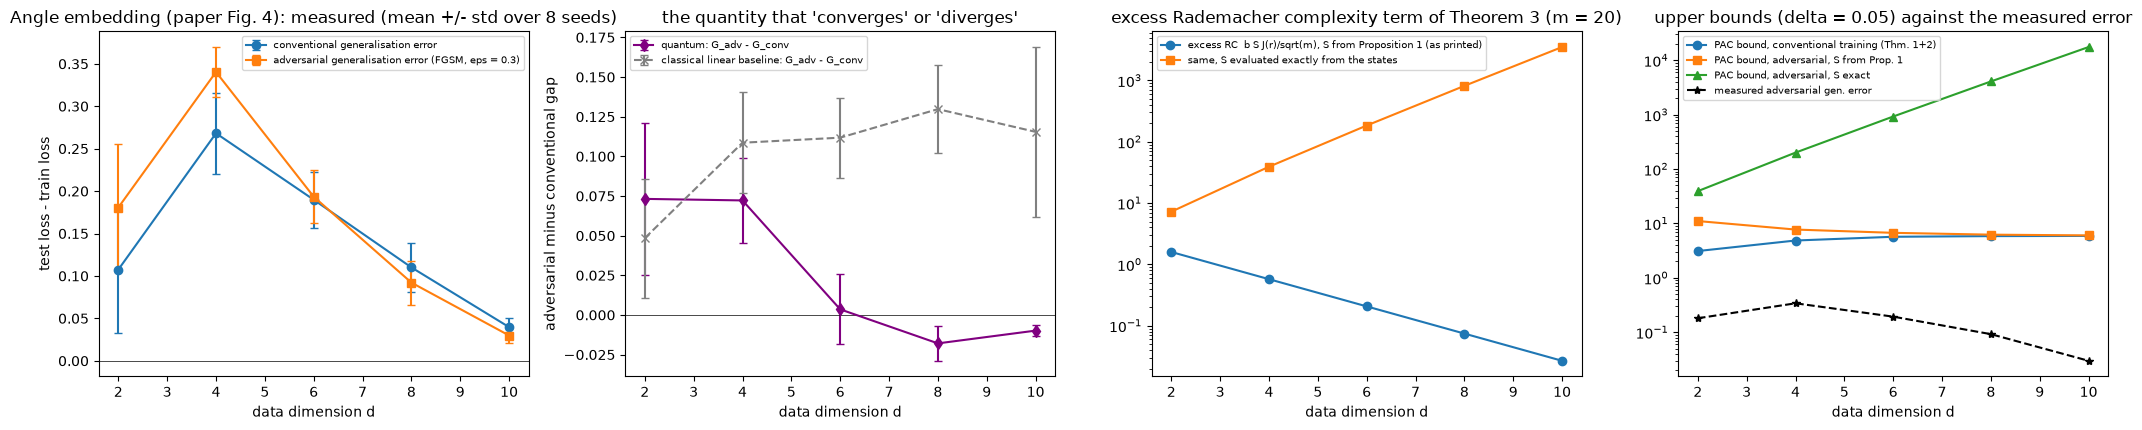

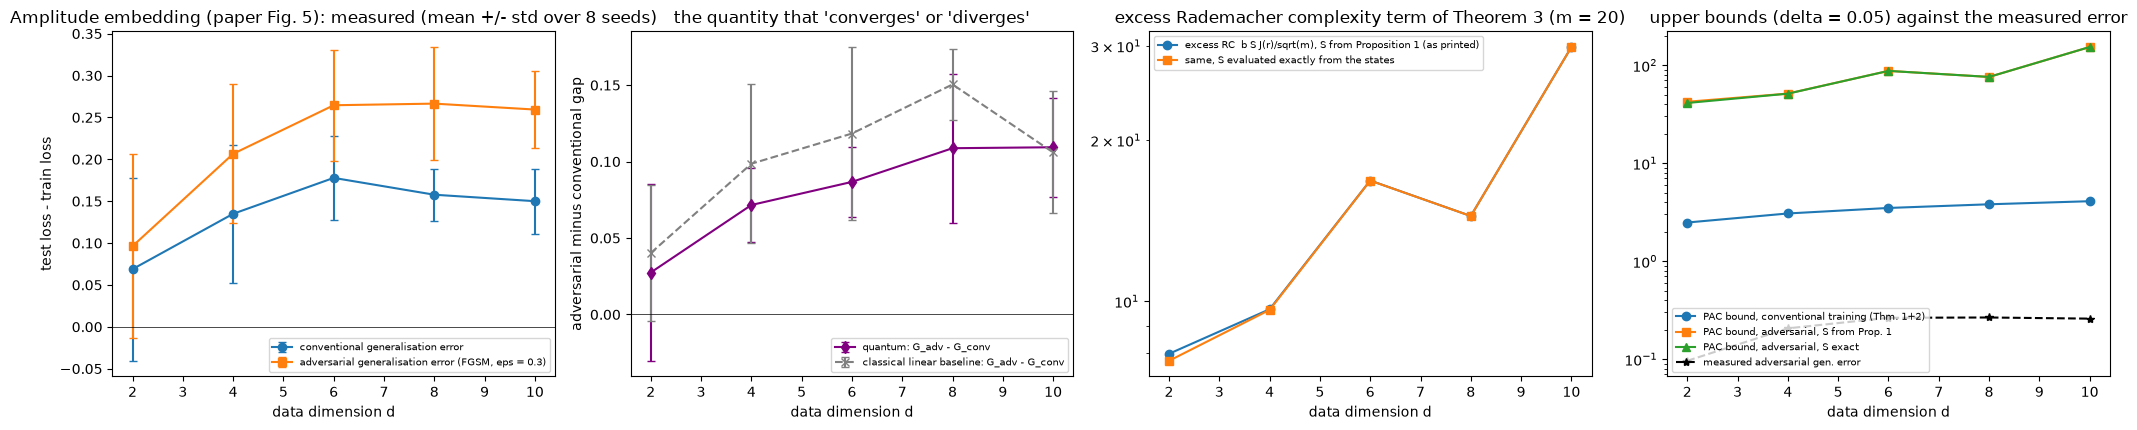

In [13]:
def fig_embedding(emb, title):
    sub = RES[RES.emb == emb]; g = sub.groupby("d")
    ds = sorted(sub.d.unique()); mean = lambda c: g[c].mean().reindex(ds).values; sd = lambda c: g[c].std().reindex(ds).values
    fig, axs = plt.subplots(1, 4, figsize=(21, 4.4))
    ax = axs[0]
    ax.errorbar(ds, mean("G_conv"), sd("G_conv"), marker="o", capsize=3, label="conventional generalisation error")
    ax.errorbar(ds, mean("G_adv"), sd("G_adv"), marker="s", capsize=3, label="adversarial generalisation error (FGSM, eps = 0.3)")
    ax.axhline(0, color="k", lw=0.5); ax.set_xlabel("data dimension d"); ax.set_ylabel("test loss - train loss"); ax.set_title(f"{title}: measured (mean +/- std over {N_SEEDS} seeds)"); ax.legend(fontsize=7)
    ax = axs[1]
    gap = (sub.G_adv - sub.G_conv).groupby(sub.d).agg(["mean", "std"]).reindex(ds)
    ax.errorbar(ds, gap["mean"], gap["std"], marker="d", color="purple", capsize=3, label="quantum: G_adv - G_conv")
    lg = (sub.lin_G_adv - sub.lin_G_conv).groupby(sub.d).agg(["mean", "std"]).reindex(ds)
    ax.errorbar(ds, lg["mean"], lg["std"], marker="x", color="gray", ls="--", capsize=3, label="classical linear baseline: G_adv - G_conv")
    ax.axhline(0, color="k", lw=0.5); ax.set_xlabel("data dimension d"); ax.set_ylabel("adversarial minus conventional gap"); ax.set_title("the quantity that 'converges' or 'diverges'"); ax.legend(fontsize=7)
    ax = axs[2]
    ax.semilogy(ds, mean("excess_rc_paper"), "o-", label="excess RC  b S J(r)/sqrt(m), S from Proposition 1 (as printed)")
    ax.semilogy(ds, mean("excess_rc_exact"), "s-", label="same, S evaluated exactly from the states")
    ax.set_xlabel("data dimension d"); ax.set_title("excess Rademacher complexity term of Theorem 3 (m = 20)"); ax.legend(fontsize=7)
    ax = axs[3]
    ax.semilogy(ds, mean("bound_conv"), "o-", label="PAC bound, conventional training (Thm. 1+2)")
    ax.semilogy(ds, mean("bound_adv_paper"), "s-", label="PAC bound, adversarial, S from Prop. 1")
    ax.semilogy(ds, mean("bound_adv_exact"), "^-", label="PAC bound, adversarial, S exact")
    ax.semilogy(ds, np.maximum(mean("G_adv"), 1e-3), "k*--", label="measured adversarial gen. error")
    ax.set_xlabel("data dimension d"); ax.set_title("upper bounds (delta = 0.05) against the measured error"); ax.legend(fontsize=7)
    plt.tight_layout(); plt.show()

fig_embedding("angle", "Angle embedding (paper Fig. 4)")
fig_embedding("amp", "Amplitude embedding (paper Fig. 5)")


## 5. Scaling with the number of training samples (paper Fig. 1 and the abstract)

The abstract states that the excess generalisation error caused by adversarial training scales as 1/sqrt(m). Figure 1 of the paper plots training and test losses of an adversarially trained angle-embedding classifier; its d is not stated, so we take d = 4 (a CHOICE) and repeat the experiment for increasing m, fitting the log-log slope of the measured errors.

m =   10 done (22 s)


m =   20 done (64 s)


m =   40 done (143 s)


m =   80 done (315 s)


m =  160 done (504 s)


,G_conv,G_conv_sd,G_adv,G_adv_sd,train_adv,test_adv,excess_rc_paper,excess_rc_exact
m,,,,,,,,
10,0.3391,0.0506,0.4322,0.0738,0.3035,0.7358,0.8109,55.3949
20,0.2447,0.0214,0.3014,0.0344,0.4248,0.7262,0.5734,39.1701
40,0.1889,0.0074,0.2093,0.0184,0.5013,0.7106,0.4055,27.6974
80,0.0105,0.0089,0.0099,0.0083,0.5265,0.5364,0.2867,19.5850
160,0.0011,0.0017,0.0005,0.0011,0.5277,0.5282,0.2027,13.8487


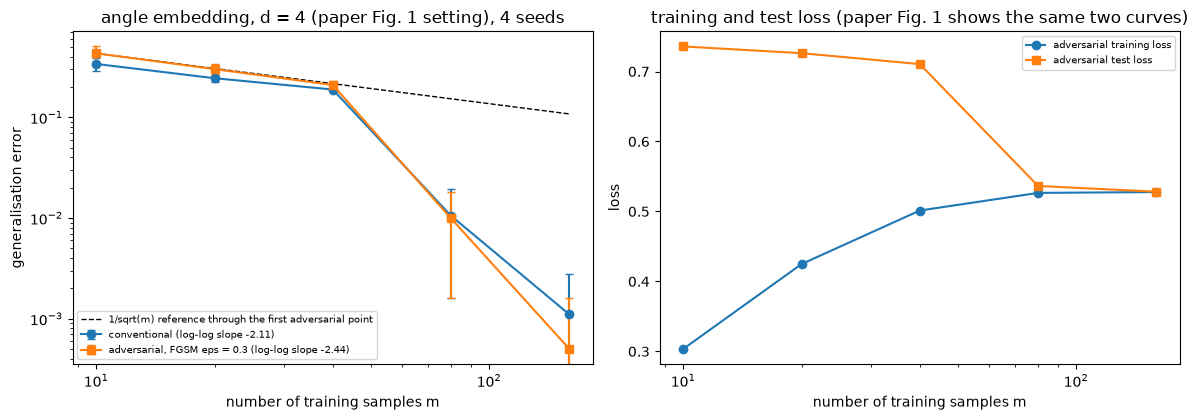

fitted exponents: adversarial gen. error ~ m^-2.44, conventional ~ m^-2.11 (the bound predicts m^-0.50)


In [14]:
t1 = time.time(); SROWS = []
for m in M_SCALE:
    for s in range(N_SEEDS_SCALE):
        SROWS.append(run_once(D_SCALE, "angle", 100 + s, m=m, with_baselines=False))
    print(f"m = {m:4d} done ({time.time() - t1:.0f} s)", flush=True)
SRES = pd.DataFrame(SROWS)
sa = SRES.groupby("m").agg(G_conv=("G_conv", "mean"), G_conv_sd=("G_conv", "std"), G_adv=("G_adv", "mean"), G_adv_sd=("G_adv", "std"),
                           train_adv=("train_adv", "mean"), test_adv=("test_adv", "mean"), excess_rc_paper=("excess_rc_paper", "mean"), excess_rc_exact=("excess_rc_exact", "mean")).round(4)
display(sa)
ms = np.array(sa.index, dtype=float)
slope_adv = np.polyfit(np.log(ms), np.log(np.maximum(sa.G_adv.values, 1e-6)), 1)[0]
slope_conv = np.polyfit(np.log(ms), np.log(np.maximum(sa.G_conv.values, 1e-6)), 1)[0]
fig, axs = plt.subplots(1, 2, figsize=(12, 4.3))
axs[0].errorbar(ms, sa.G_conv, sa.G_conv_sd, marker="o", capsize=3, label=f"conventional (log-log slope {slope_conv:+.2f})")
axs[0].errorbar(ms, sa.G_adv, sa.G_adv_sd, marker="s", capsize=3, label=f"adversarial, FGSM eps = 0.3 (log-log slope {slope_adv:+.2f})")
axs[0].plot(ms, sa.G_adv.values[0] * np.sqrt(ms[0] / ms), "k--", lw=1, label="1/sqrt(m) reference through the first adversarial point")
axs[0].set_xscale("log"); axs[0].set_yscale("log"); axs[0].set_xlabel("number of training samples m"); axs[0].set_ylabel("generalisation error")
axs[0].set_title(f"angle embedding, d = {D_SCALE} (paper Fig. 1 setting), {N_SEEDS_SCALE} seeds"); axs[0].legend(fontsize=7)
axs[1].plot(ms, sa.train_adv, "o-", label="adversarial training loss"); axs[1].plot(ms, sa.test_adv, "s-", label="adversarial test loss")
axs[1].set_xscale("log"); axs[1].set_xlabel("number of training samples m"); axs[1].set_ylabel("loss"); axs[1].set_title("training and test loss (paper Fig. 1 shows the same two curves)"); axs[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
print(f"fitted exponents: adversarial gen. error ~ m^{slope_adv:+.2f}, conventional ~ m^{slope_conv:+.2f} (the bound predicts m^-0.50)")


## 6. Experiment B: quantum attacks and noisy embeddings (paper Fig. 6)

Amplitude embedding of d = 6 inputs into 3 qubits (dH = 8). One classifier is trained on noiseless embedded states and one on noisy states (`rho' = (1 - lambda_min dH) rho + lambda_min I`, lambda_min = 0.011); both are adversarially trained against the quantum FGSM adversary of strength 0.001 and then evaluated against the same adversary for eps in the grid [0.001, 0.01]. The bounds are the Theorem 3 bound (quantum attack, `S^Q <= eps dH^2` for r = p = infinity), the tighter Theorem 4 bound that is valid for the noisy states (Assumption 1: smallest eigenvalue 0.011 is at least eps), and the conventional bound.

noiseless embedding done (159 s)


noisy   embedding done (389 s)


minimum eigenvalue of a noisy embedded state (paper: 0.011, Assumption 1 needs >= eps): 0.011


G_conv   G_adv  G_adv_sd  train_adv  test_adv  R_thm2  bound_conv  bound_thm3  bound_thm4
embedding                   eps                                                                                              
noiseless                   0.0010  0.2051  0.2052    0.0433     0.0645    0.2698  0.5127      3.4747      4.1826      3.4837
                            0.0025  0.2051  0.2055    0.0434     0.0647    0.2702  0.5127      3.4747      5.2445      3.4971
                            0.0040  0.2051  0.2058    0.0434     0.0649    0.2707  0.5127      3.4747      6.3063      3.5105
                            0.0055  0.2051  0.2060    0.0435     0.0651    0.2711  0.5127      3.4747      7.3682      3.5239
                            0.0070  0.2051  0.2062    0.0436     0.0654    0.2716  0.5127      3.4747      8.4300      3.5373
                            0.0085  0.2051  0.2066    0.0437     0.0655    0.2721  0.5127      3.4747      9.4919      3.5508
                            0.0100  0.2051  0.2068    0.0438     0.0657    0.2725  0.5127      3.4747     10.5537      3.5642
noisy (global depolarising) 0.0010  0.1949  0.1951    0.0433     0.0710    0.2660  0.4784      3.3031      4.0110      3.3120
                            0.0025  0.1949  0.1953    0.0434     0.0712    0.2665  0.4784      3.3031      5.0728      3.3255
                            0.0040  0.1949  0.1956    0.0435     0.0714    0.2670  0.4784      3.3031      6.1347      3.3389
                            0.0055  0.1949  0.1958    0.0436     0.0717    0.2675  0.4784      3.3031      7.1965      3.3523
                            0.0070  0.1949  0.1961    0.0437     0.0719    0.2680  0.4784      3.3031      8.2584      3.3657
                            0.0085  0.1949  0.1965    0.0438     0.0721    0.2685  0.4784      3.3031      9.3202      3.3791
                            0.0100  0.1949  0.1967    0.0438     0.0723    0.2689  0.4784      3.3031     10.3821      3.3925

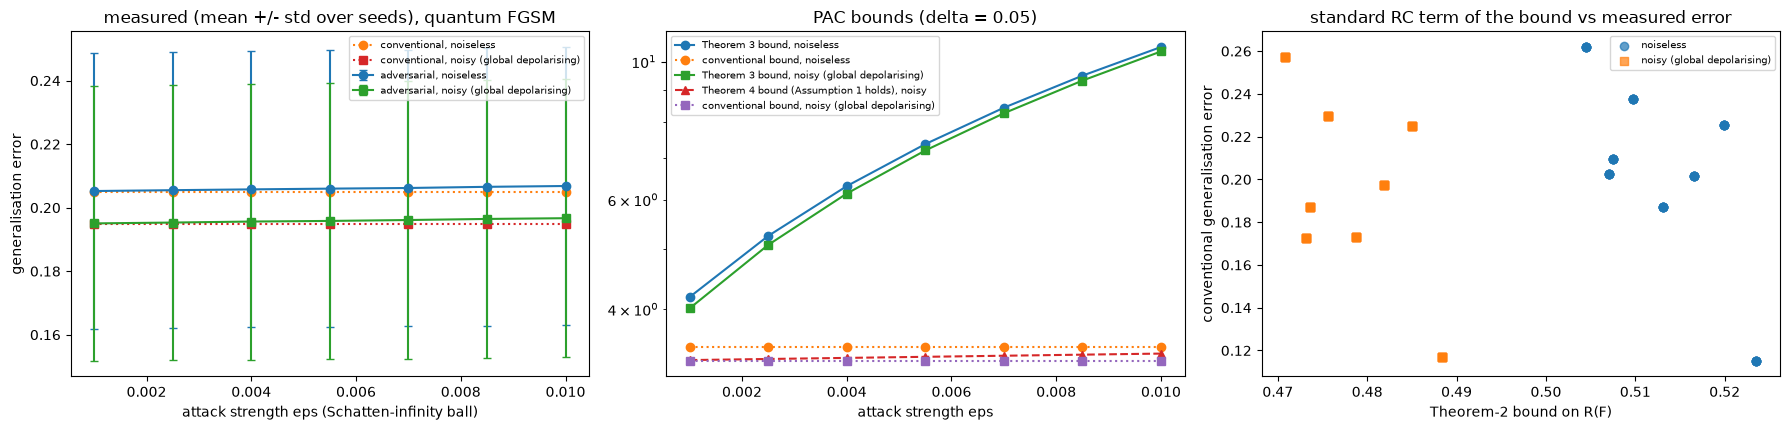

In [15]:
t1 = time.time(); QROWS = []
for noisy in (False, True):
    for s in range(N_SEEDS):
        QROWS += run_quantum_attack(s, noisy)
    print(("noisy  " if noisy else "noiseless"), f"embedding done ({time.time() - t1:.0f} s)", flush=True)
QRES = pd.DataFrame(QROWS); QRES["embedding"] = np.where(QRES.noisy, "noisy (global depolarising)", "noiseless")
print("minimum eigenvalue of a noisy embedded state (paper: 0.011, Assumption 1 needs >= eps):",
      round(float(torch.linalg.eigvalsh(noisy_density(density(torch.tensor(draw_data(D_Q, 50, np.random.default_rng(0))[0])))).min()), 4))
qa = QRES.groupby(["embedding", "eps"]).agg(G_conv=("G_conv", "mean"), G_adv=("G_adv", "mean"), G_adv_sd=("G_adv", "std"), train_adv=("train_adv", "mean"), test_adv=("test_adv", "mean"),
                                           R_thm2=("R_thm2", "mean"), bound_conv=("bound_conv", "mean"), bound_thm3=("bound_adv_thm3", "mean"), bound_thm4=("bound_adv_thm4", "mean")).round(4)
display(qa)

fig, axs = plt.subplots(1, 3, figsize=(18, 4.4))
for emb_name, mk in (("noiseless", "o"), ("noisy (global depolarising)", "s")):
    q = QRES[QRES.embedding == emb_name].groupby("eps")
    e = sorted(QRES.eps.unique())
    axs[0].errorbar(e, q.G_adv.mean().reindex(e), q.G_adv.std().reindex(e), marker=mk, capsize=3, label=f"adversarial, {emb_name}")
    axs[0].plot(e, q.G_conv.mean().reindex(e), marker=mk, ls=":", label=f"conventional, {emb_name}")
    axs[1].plot(e, q.bound_adv_thm3.mean().reindex(e), marker=mk, label=f"Theorem 3 bound, {emb_name}")
    if emb_name != "noiseless":
        axs[1].plot(e, q.bound_adv_thm4.mean().reindex(e), marker="^", ls="--", label="Theorem 4 bound (Assumption 1 holds), noisy")
    axs[1].plot(e, q.bound_conv.mean().reindex(e), marker=mk, ls=":", label=f"conventional bound, {emb_name}")
axs[0].set_xlabel("attack strength eps (Schatten-infinity ball)"); axs[0].set_ylabel("generalisation error"); axs[0].set_title("measured (mean +/- std over seeds), quantum FGSM"); axs[0].legend(fontsize=7)
axs[1].set_yscale("log"); axs[1].set_xlabel("attack strength eps"); axs[1].set_title("PAC bounds (delta = 0.05)"); axs[1].legend(fontsize=7)
for emb_name, mk in (("noiseless", "o"), ("noisy (global depolarising)", "s")):
    q = QRES[(QRES.embedding == emb_name)]
    axs[2].scatter(q.R_thm2, q.G_conv, marker=mk, alpha=0.7, label=emb_name)
axs[2].set_xlabel("Theorem-2 bound on R(F)"); axs[2].set_ylabel("conventional generalisation error"); axs[2].set_title("standard RC term of the bound vs measured error"); axs[2].legend(fontsize=7)
plt.tight_layout(); plt.show()


## 7. Classical baselines on identical inputs

All models see exactly the same 20 training samples and the same 1000 test samples. The adversarially trained linear model uses the same loss, FGSM and Adam budget; the random forest and the RBF-SVC are the standard non-adversarial baselines (clean accuracy only, they have no gradient for FGSM). The Bayes-optimal accuracy of the generator is shown as the ceiling. This table also puts the generalisation errors above into context: a classifier that generalises "well" because it learned nothing is not a good classifier.

quantum_clean_acc  quantum_adv_acc  linear_clean_acc  linear_adv_acc  RF_clean_acc  SVC_rbf_clean_acc  quantum_G_adv  linear_G_adv  quantum_G_conv  linear_G_conv  Bayes_optimal_acc
d  emb                                                                                                                                                                                        
2  amp                0.617            0.450             0.694           0.607         0.697              0.694          0.096         0.149           0.069          0.109              0.784
   angle              0.528            0.306             0.684           0.604         0.728              0.715          0.181         0.151           0.107          0.102              0.784
4  amp                0.666            0.446             0.767           0.626         0.770              0.787          0.207         0.147           0.135          0.049              0.867
   angle              0.525            0.149             0.812           0.685         0.817              0.818          0.340         0.183           0.268          0.075              0.867
6  amp                0.760            0.514             0.860           0.711         0.841              0.869          0.265         0.173           0.178          0.055              0.913
   angle              0.513            0.094             0.867           0.730         0.854              0.859          0.193         0.174           0.190          0.062              0.913
8  amp                0.814            0.541             0.902           0.741         0.861              0.904          0.266         0.189           0.158          0.039              0.942
   angle              0.505            0.071             0.866           0.723         0.859              0.887          0.092         0.177           0.110          0.047              0.942
10 amp                0.836            0.558             0.880           0.736         0.880              0.918          0.259         0.138           0.150          0.032              0.960
   angle              0.495            0.060             0.891           0.728         0.862              0.890          0.030         0.166           0.040          0.051              0.960

All models see exactly the same m = 20 training samples and the same 1000 test samples; the linear model is trained with the same loss, the same FGSM (eps = 0.3) and the same Adam budget.
RF and SVC(rbf) have no gradients here, so they are shown on clean data only. 'Bayes_optimal_acc' is the accuracy of the true likelihood-ratio rule of the generator.


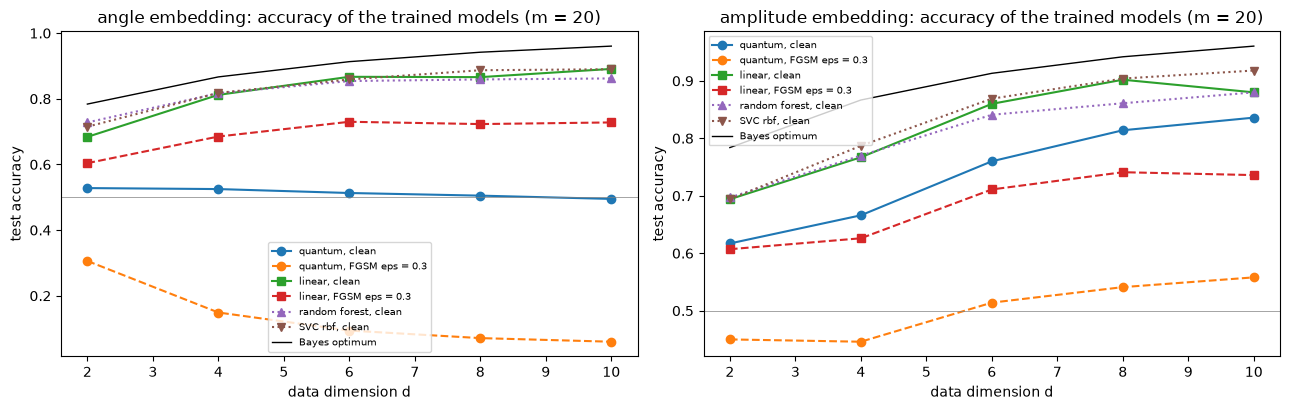

In [16]:
cmp = RES.groupby(["d", "emb"]).agg(
    quantum_clean_acc=("acc_test_clean", "mean"), quantum_adv_acc=("acc_test_adv", "mean"),
    linear_clean_acc=("lin_acc_test_clean", "mean"), linear_adv_acc=("lin_acc_test_adv", "mean"),
    RF_clean_acc=("rf_acc_test", "mean"), SVC_rbf_clean_acc=("svc_acc_test", "mean"),
    quantum_G_adv=("G_adv", "mean"), linear_G_adv=("lin_G_adv", "mean"), quantum_G_conv=("G_conv", "mean"), linear_G_conv=("lin_G_conv", "mean")).round(3)
cmp["Bayes_optimal_acc"] = [round(bayes_accuracy(d), 3) for d, _ in cmp.index]
display(cmp)
print("All models see exactly the same m = 20 training samples and the same 1000 test samples; the linear model is trained with the same loss, the same FGSM (eps = 0.3) and the same Adam budget.")
print("RF and SVC(rbf) have no gradients here, so they are shown on clean data only. 'Bayes_optimal_acc' is the accuracy of the true likelihood-ratio rule of the generator.")
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, emb, ttl in ((axs[0], "angle", "angle embedding"), (axs[1], "amp", "amplitude embedding")):
    s = cmp.xs(emb, level="emb"); ds = list(s.index)
    ax.plot(ds, s.quantum_clean_acc, "o-", label="quantum, clean"); ax.plot(ds, s.quantum_adv_acc, "o--", label="quantum, FGSM eps = 0.3")
    ax.plot(ds, s.linear_clean_acc, "s-", label="linear, clean"); ax.plot(ds, s.linear_adv_acc, "s--", label="linear, FGSM eps = 0.3")
    ax.plot(ds, s.RF_clean_acc, "^:", label="random forest, clean"); ax.plot(ds, s.SVC_rbf_clean_acc, "v:", label="SVC rbf, clean")
    ax.plot(ds, [bayes_accuracy(d) for d in ds], "k-", lw=1, label="Bayes optimum"); ax.axhline(0.5, color="gray", lw=0.5)
    ax.set_xlabel("data dimension d"); ax.set_ylabel("test accuracy"); ax.set_title(f"{ttl}: accuracy of the trained models (m = 20)"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()


## 8. Paper versus this notebook

One row per checkable claim. Verdict rules (fixed before looking at the numbers): a *trend* claim is "reproduced" when the measured quantity moves in the stated direction and a Welch t-test across the independent repetitions gives p < 0.05, "direction reproduced, not significant" when it moves the right way without significance, and "not reached" when it moves the other way; an *inequality* claim is "reproduced" when it holds in every evaluated case; a claim that needs a range or precision we do not have is "cannot be checked". The paper publishes no numerical tables, so no verdict is about a number.

In [17]:
def gap_matrix(emb):
    sub = RES[RES.emb == emb]
    return (sub.G_adv - sub.G_conv).groupby([sub.seed, sub.d]).mean().unstack(1)       # seeds x d

def trend(emb):
    P = gap_matrix(emb); d0, d1 = P.columns[0], P.columns[-1]
    t = stats.ttest_ind(P[d1], P[d0], equal_var=False)
    return d0, d1, P[d0].mean(), P[d1].mean(), float(t.pvalue)

def verdict_direction(expected_sign, g0, g1, p):
    delta = g1 - g0
    if np.sign(delta) != expected_sign:
        return "not reached (the gap moves the other way)"
    return "reproduced (significant, p = %.3f)" % p if p < 0.05 else "direction reproduced, not significant (p = %.2f)" % p

V = []
d0, d1, g0, g1, p = trend("angle")
V.append(("Fig. 4: angle embedding, classical attack: adversarial and conventional generalisation errors converge as d grows",
          "converge (figure, no numbers)", f"gap G_adv - G_conv: {g0:+.3f} at d = {d0} -> {g1:+.3f} at d = {d1}", verdict_direction(-1, g0, g1, p)))
d0, d1, g0, g1, p = trend("amp")
V.append(("Fig. 5: amplitude embedding, classical attack: the two errors diverge as d grows",
          "diverge (figure, no numbers)", f"gap G_adv - G_conv: {g0:+.3f} at d = {d0} -> {g1:+.3f} at d = {d1}", verdict_direction(+1, g0, g1, p)))
P = gap_matrix("amp").mean(0).values
V.append(("Fig. 5 text: the amplitude-embedding gap plateaus at higher d", "plateau (text)", "mean gap by d: " + ", ".join(f"{x:+.3f}" for x in P),
          "cannot be checked (our d range is too short to see a plateau)"))
# quantum attack: G_adv increases with eps
slopes = {}
for name in ("noiseless", "noisy (global depolarising)"):
    q = QRES[QRES.embedding == name]
    sl = np.array([np.polyfit(g.eps.values, g.G_adv.values, 1)[0] for _, g in q.groupby("seed")])
    slopes[name] = sl
    tt = stats.ttest_1samp(sl, 0.0)
    V.append((f"Fig. 6: adversarial generalisation error increases with eps ({name} embedding, quantum FGSM)", "increases with eps (figure)",
              f"mean slope dG_adv/deps = {sl.mean():+.3f}; {int((sl > 0).sum())}/{len(sl)} seeds positive", "reproduced (significant, p = %.3f)" % tt.pvalue if (sl.mean() > 0 and tt.pvalue < 0.05)
              else ("direction reproduced, not significant (p = %.2f)" % tt.pvalue if sl.mean() > 0 else "not reached")))
for lab, col in (("conventional", "G_conv"), ("adversarial (eps = 0.001)", "G_adv")):
    q0 = QRES[(QRES.eps == min(EPS_Q_GRID))]
    a = q0[~q0.noisy].sort_values('seed')[col].values; b = q0[q0.noisy].sort_values('seed')[col].values
    tt = stats.ttest_rel(b, a)     # paired: same data and initial weights per seed
    V.append((f"Fig. 6: the noisy embedding has a lower {lab} generalisation error than the noiseless one", "lower (figure)", f"noisy {b.mean():.3f} vs noiseless {a.mean():.3f} (mean over {len(a)} seeds)",
              ("reproduced (significant, p = %.3f)" % tt.pvalue if (b.mean() < a.mean() and tt.pvalue < 0.05) else
               ("direction reproduced, not significant (p = %.2f)" % tt.pvalue if b.mean() < a.mean() else "not reached"))))
# 1/sqrt(m) and bounds
V.append(("Abstract / Table I: the excess generalisation error scales as 1/sqrt(m) (Fig. 1 setting: angle embedding, d = %d)" % D_SCALE, "G ~ m^-0.5 (upper bound)",
          f"measured exponents: adversarial {slope_adv:+.2f}, conventional {slope_conv:+.2f}",
          "reproduced (decay at least as fast as m^-0.5)" if slope_adv <= -0.4 else ("not reached (decays slower than m^-0.5)" if slope_adv > -0.25 else "partly: decays, slower than m^-0.5")))
ok_paper = float((RES.G_adv <= RES.bound_adv_paper).mean()); ok_exact = float((RES.G_adv <= RES.bound_adv_exact).mean())
ratio = float(np.median(RES.bound_adv_exact / np.maximum(RES.G_adv, 1e-3)))
V.append(("Theorems 1-3: the PAC bound lies above the measured adversarial generalisation error", "bound >= error",
          f"holds in {100 * ok_paper:.0f} % of runs (S from Prop. 1) and {100 * ok_exact:.0f} % (S exact); median bound/error ratio {ratio:.0f}x", "reproduced as an inequality, but the bound is vacuous at m = 20 (values far above 1)"))
ang = pd.DataFrame([dict(d=d, ok=S_paper("angle", d, EPS_C, None) >= S_exact("angle", d, EPS_C, None)) for d in D_LIST])
V.append(("Proposition 1 (angle embedding): S <= 2L(2 eps)^d, decaying exponentially with d", "valid upper bound on S", f"holds for {int(ang.ok.sum())} of {len(ang)} dimensions tested (exact S grows like 2^d)",
          "not reproduced: the printed bound lies below the exact value (see the check above)" if not ang.ok.all() else "reproduced"))
amp = pd.DataFrame([dict(d=d, ok=S_paper("amp", d, EPS_C, draw_data(d, M_TRAIN, np.random.default_rng(d))[0]) >= S_exact("amp", d, EPS_C, draw_data(d, M_TRAIN, np.random.default_rng(d))[0]) - 1e-9) for d in D_LIST])
V.append(("Proposition 1 (amplitude embedding): S <= 2^(1+ceil(log2 d)) min{eps max(1, d^(1/2-1/p)) / min ||x||, 1}", "valid upper bound on S", f"holds for {int(amp.ok.sum())} of {len(amp)} dimensions tested",
          "reproduced" if amp.ok.all() else "not reproduced"))
qq = QRES.groupby("embedding").R_thm2.mean()
V.append(("Fig. 6 / Theorem 2: the standard Rademacher-complexity bound R(F) is smaller for the noisy embedding", "R(F) decreases with noise", f"mean Thm-2 bound: noisy {qq['noisy (global depolarising)']:.3f} vs noiseless {qq['noiseless']:.3f}",
          "reproduced" if qq['noisy (global depolarising)'] < qq['noiseless'] else "not reached"))
nz = QRES[QRES.noisy]
V.append(("Theorem 4 is tighter than Theorem 3 for noisy embeddings (Assumption 1 holds: lambda_min = %.3f >= eps)" % LAMBDA_MIN, "tighter (text)", f"bound at eps = {max(EPS_Q_GRID)}: Thm 4 {nz[nz.eps == max(EPS_Q_GRID)].bound_adv_thm4.mean():.2f} vs Thm 3 {nz[nz.eps == max(EPS_Q_GRID)].bound_adv_thm3.mean():.2f}",
          "reproduced" if (nz.bound_adv_thm4 < nz.bound_adv_thm3).all() else "not reached"))
VERD = pd.DataFrame(V, columns=["claim of the paper", "paper", "this notebook", "verdict"])
pd.set_option("display.max_colwidth", 200)
display(VERD)
print(VERD.verdict.str.split(" ").str[0].value_counts().to_string())


,claim of the paper,paper,this notebook,verdict
0,"Fig. 4: angle embedding, classical attack: adversarial and conventional generalisation errors converge as d grows","converge (figure, no numbers)",gap G_adv - G_conv: +0.073 at d = 2 -> -0.010 at d = 10,"reproduced (significant, p = 0.002)"
1,"Fig. 5: amplitude embedding, classical attack: the two errors diverge as d grows","diverge (figure, no numbers)",gap G_adv - G_conv: +0.027 at d = 2 -> +0.109 at d = 10,"reproduced (significant, p = 0.005)"
2,Fig. 5 text: the amplitude-embedding gap plateaus at higher d,plateau (text),"mean gap by d: +0.027, +0.072, +0.087, +0.109, +0.109",cannot be checked (our d range is too short to see a plateau)
3,"Fig. 6: adversarial generalisation error increases with eps (noiseless embedding, quantum FGSM)",increases with eps (figure),mean slope dG_adv/deps = +0.174; 8/8 seeds positive,"reproduced (significant, p = 0.000)"
4,"Fig. 6: adversarial generalisation error increases with eps (noisy (global depolarising) embedding, quantum FGSM)",increases with eps (figure),mean slope dG_adv/deps = +0.182; 8/8 seeds positive,"reproduced (significant, p = 0.000)"
5,Fig. 6: the noisy embedding has a lower conventional generalisation error than the noiseless one,lower (figure),noisy 0.195 vs noiseless 0.205 (mean over 8 seeds),"reproduced (significant, p = 0.036)"
6,Fig. 6: the noisy embedding has a lower adversarial (eps = 0.001) generalisation error than the noiseless one,lower (figure),noisy 0.195 vs noiseless 0.205 (mean over 8 seeds),"reproduced (significant, p = 0.036)"
7,"Abstract / Table I: the excess generalisation error scales as 1/sqrt(m) (Fig. 1 setting: angle embedding, d = 4)",G ~ m^-0.5 (upper bound),"measured exponents: adversarial -2.44, conventional -2.11",reproduced (decay at least as fast as m^-0.5)
8,Theorems 1-3: the PAC bound lies above the measured adversarial generalisation error,bound >= error,holds in 100 % of runs (S from Prop. 1) and 100 % (S exact); median bound/error ratio 536x,"reproduced as an inequality, but the bound is vacuous at m = 20 (values far above 1)"
9,"Proposition 1 (angle embedding): S <= 2L(2 eps)^d, decaying exponentially with d",valid upper bound on S,holds for 0 of 5 dimensions tested (exact S grows like 2^d),not reproduced: the printed bound lies below the exact value (see the check above)


verdict
reproduced    11
cannot         1
not            1


In [18]:

print(f"Total wall-clock time of the notebook: {(time.time() - T0) / 60:.1f} minutes (FAST_MODE = {FAST_MODE})")


Total wall-clock time of the notebook: 38.8 minutes (FAST_MODE = False)


## 9. Reading the paper critically

* **The bounds are vacuous at the sample size used.** With m = 20 and a 95 % confidence, the confidence term of Theorem 1 alone is `3 sqrt(ln(40)/40) = 0.91`, and the Rademacher terms multiply a Lipschitz constant alpha/4 = 2.5; the printed PAC bounds are therefore far above 1 for a loss that lives in [0, 1], while the measured generalisation errors are a few tenths. The bounds are "true" but carry no numerical information; the paper's figures can only support *trends*, not tightness (the authors say as much: uniform-convergence bounds are not tight).
* **Proposition 1 for rotation embeddings does not survive a numerical check as printed.** For the angle embedding the printed `S = 2L (2 eps)^d` decays with d, but the exact value of `dH sup ||rho(x) - rho(x')||_1` is `2^(d+1) sqrt(1 - cos(eps)^(2d))`, which grows with d (section 3 shows the trace distance reproduced with the simulated states). The proof in Appendix E bounds the diamond distance of a tensor product of single-qubit rotations by the product of the single-qubit distances, which is not a valid step (a product of differences is not the difference of products); the correct bound scales with `||delta||_1` rather than `prod_j |delta_j|`. If we read the proof correctly, the headline "rotation embeddings generalise like conventional training when d is large" is not implied by the theorem; what the measured gaps show is an empirical trend for this particular data set, not a consequence of the bound. The amplitude-embedding formula, in contrast, is a valid (and nearly tight) upper bound in our test.
* **A small generalisation gap is not the same as a good classifier.** The measured gaps for the angle embedding shrink with d, but the baseline table shows that the classifier is close to chance on the test set for most d: with unit-variance noise and class means only pi/4 apart, the trigonometric score function carries little usable signal, so training loss and test loss are both high and the gap says little. Under the attack at eps = 0.3 the signal is also drowned: moving every rotation angle by 0.3 changes sin(2x) by far more than the class means differ (about 0.14 after the Gaussian smoothing), the adversarial training loss stays close to 0.5 (the loss of the constant score f = 0) for the larger d, and the adversarial test accuracy of the angle-embedding classifier falls below chance. Generalisation error (test minus training loss) must always be read together with the training loss. The classical linear baseline and the random forest reach much higher clean accuracy on the same 20 samples (see section 7).
* **The quantum attack is weak by construction.** An operator-norm ball of radius 0.001 to 0.01 around a pure 3-qubit state, searched with a layer of single-qubit rotations and a single FGSM step, changes the loss only in the third decimal, so the adversarial and conventional generalisation errors differ in the third or fourth decimal. The monotone growth with eps is visible, but the effect is tiny; the paper's figure cannot show more.
* **Equal behaviour of noisy and noiseless embeddings is nearly built in.** The global depolarising channel with `q = lambda_min dH = 0.088` multiplies the score by `1 - q` (the observable is traceless), so the noisy classifier is the noiseless one with a slightly flatter loss; a lower generalisation error follows mostly from the smaller effective margin, which the paper explains through the smaller R(F).
* **The m-scaling is not a clean power law here.** With a fixed 40 epochs the number of optimiser steps grows with m and, at the larger sample sizes, the adversarially trained model stays close to the constant score (training and test adversarial loss almost coincide), so the measured gap collapses faster than m^-0.5. A measured exponent steeper than -0.5 is compatible with an upper bound of that order but does not confirm its tightness, and with four or five values of m the fit is crude.
* **Several choices decide the outcome and are unspecified:** the optimiser, learning rate, batch size and initialisation; how n expectation values become one score; the loss sign convention; the set of dimensions d; the structure of the adversary's channel U_theta; the number of repetitions. We fixed them and flagged each with `CHOICE`.
* **Single-step FGSM is not the worst case.** The theory is stated for the maximising adversary; the experiments use FGSM, which under-estimates the adversarial loss, so measured adversarial gaps are lower bounds on the true ones for these classifiers.

## 10. Exercises

1. **Stronger attack.** Replace FGSM in `fgsm_c` by a 10-step PGD with projection onto the l_infinity ball of radius 0.3. Does the adversarial generalisation error of the angle embedding still approach the conventional one as d grows?
2. **More data.** Re-run section 5 with `M_SCALE` up to 1280 (use `FAST_MODE = False` and a longer budget). Does the measured exponent approach -0.5, or is it steeper? Why can an upper bound of order `m^(-1/2)` be loose?
3. **Re-uploading.** Implement an L = 2 data re-uploading circuit (embedding, trainable layer, embedding, trainable layer) and compare the printed Proposition 1 (`2L(2 eps)^d`) with the exact `S` computed from the simulated states, as in section 3. Which L-dependence do you find?
4. **A stronger quantum adversary.** Replace the `Rot` layer of the attacker by a layer with CNOTs and several parameter blocks, or optimise `theta` with 20 gradient-ascent steps projected onto the norm ball. How much larger do the adversarial generalisation errors of Fig. 6 become?
5. **Make the bound informative.** Find the smallest m for which the full PAC bound of Theorem 1 combined with Theorem 3 drops below 1 for the angle embedding at d = 4 (use the exact S). Compare with the m = 20 used by the paper and discuss what the figures of the paper therefore show.